# 1. SMILES Classification

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import pandas as pd
import requests
import os
import tqdm
from datetime import datetime


timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_file = f"data/nist23_data/test23/test_with_classification_{timestamp}.csv"

# ==============================================================
# Step 1: Load or Initialize DataFrame
# ==============================================================
# Check if we have an incomplete progress file to resume
print("Starting from scratch...")
with open('data/nist23_data/test23/test.json', 'r') as f:
    test_data = json.load(f)

df = pd.DataFrame(test_data)[['smiles', 'peaks', 'molecular_weight']]
df['rank23'] = ''  # Add empty rank23 column

# Initialize as None to indicate "Not Processed Yet"
df['superclass'] = None
df['class'] = None
df = df[['smiles', 'superclass', 'class', 'rank23', 'peaks', 'molecular_weight']]

# ==============================================================
# Step 2: Fetch classification results for each SMILES
# ==============================================================
# url = 'https://npclassifier.gnps2.org/classify?smiles='
url = 'https://structure.gnps2.org/classyfire?smiles='
# url = 'https://npclassifier.ucsd.edu/classify?smiles='

for i, row in tqdm.tqdm(df.iterrows(), total=len(df)):
    # Only fetch if it is literally NaN/None (unprocessed)
    if pd.isna(row['superclass']) or pd.isna(row['class']):
        try:
            response = requests.get(url + row['smiles'], timeout=10)
            
            if response.status_code == 200:
                data = response.json()
                val_super = data.get("superclass") or {}
                val_class = data.get("class") or {}
                
                # CRITICAL FIX: If no name exists, mark as "Unclassified" instead of None
                # This prevents the script from forever retrying molecules without a category
                df.loc[i, 'superclass'] = val_super.get("name") or "Unclassified"
                df.loc[i, 'class'] = val_class.get("name") or "Unclassified"
                
            else:
                # If the API throws 404/500, mark as "Error_API" so we don't get stuck
                df.loc[i, 'superclass'] = "Error_API"
                df.loc[i, 'class'] = "Error_API"
                
        except Exception as e:
            # Proper network timeout/error: do nothing, leave as None to retry next time
            pass
            
        # Save progress every 100 entries
        if i > 0 and i % 100 == 0:
            df.to_csv(output_file, index=False)
            # time.sleep(1)  # Uncomment to avoid API rate limiting

# ==============================================================
# Step 3: Final Save
# ==============================================================
df.to_csv(output_file, index=False)
print(f"All done! Final file saved as: {output_file}")

Starting from scratch...


  5%|▌         | 1146/20916 [29:51<8:35:02,  1.56s/it] 



KeyboardInterrupt: 

In [ ]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import pandas as pd
import requests
import os
import tqdm
from datetime import datetime
import urllib.parse


timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_file = f"data/nist23_data/test23/test_with_classification_{timestamp}.csv"

# ==============================================================
# Step 1: Load or Initialize DataFrame
# ==============================================================
# Check if we have an incomplete progress file to resume
print("Starting from scratch...")
with open('data/nist23_data/test23/test.json', 'r') as f:
    test_data = json.load(f)

df = pd.DataFrame(test_data)[['smiles', 'peaks', 'molecular_weight']]
df['rank23'] = ''  # Add empty rank23 column

# Initialize as None to indicate "Not Processed Yet"
df['superclass'] = None
df['class'] = None
df = df[['smiles', 'superclass', 'class', 'rank23', 'peaks', 'molecular_weight']]

# ==============================================================
# Step 2: Fetch classification results for each SMILES
# ==============================================================
url = 'https://npclassifier.gnps2.org/classify?smiles='
# url = 'https://npclassifier.ucsd.edu/classify?smiles='

for i, row in tqdm.tqdm(df.iterrows(), total=len(df)):
    # Only fetch if it is literally NaN/None (unprocessed)
    if pd.isna(row['superclass']) or pd.isna(row['class']):
        try:
            safe_smiles = urllib.parse.quote(row['smiles'])
            response = requests.get(url + safe_smiles, timeout=10)
            
            if response.status_code == 200:
                data = response.json()
                
                # NPClassifier 返回的是列表，比如 ["Fatty acyls"]
                val_super_list = data.get("superclass_results") or []
                val_class_list = data.get("class_results") or []
                
                # 提取列表第一个元素，如果没有则为 "Unclassified"
                df.loc[i, 'superclass'] = val_super_list[0] if val_super_list else "Unclassified"
                df.loc[i, 'class'] = val_class_list[0] if val_class_list else "Unclassified"
                
            else:
                # If the API throws 404/500, mark as "Error_API" so we don't get stuck
                df.loc[i, 'superclass'] = "Error_API"
                df.loc[i, 'class'] = "Error_API"
                
        except Exception as e:
            # Proper network timeout/error: do nothing, leave as None to retry next time
            pass
            
        # Save progress every 100 entries
        if i > 0 and i % 100 == 0:
            df.to_csv(output_file, index=False)
            # time.sleep(1)  # Uncomment to avoid API rate limiting

# ==============================================================
# Step 3: Final Save
# ==============================================================
df.to_csv(output_file, index=False)
print(f"All done! Final file saved as: {output_file}")

Starting from scratch...


  1%|          | 120/20916 [02:57<8:31:39,  1.48s/it]



KeyboardInterrupt: 

In [2]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import pandas as pd
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_file = f"data/nist23_data/test23/test_smiles_with_classification_{timestamp}.csv"

# Step 1: Load test set from JSON
print("1. Loading test set JSON...")
with open('data/nist23_data/test23/test.json', 'r') as f:
    test_data = json.load(f)

# Convert to DataFrame, keep basic columns
df = pd.DataFrame(test_data)[['smiles', 'peaks', 'molecular_weight']]

# Step 2: Load reference CSV and build lookup dictionaries
print("2. Building lookup dictionaries from CSV...")
csv_ref_path = "data/nist23_data/test23/test_unismiles_rank23_class_results.csv"
df_ref = pd.read_csv(csv_ref_path)
superclass_dict = dict(zip(df_ref['smiles'], df_ref['superclass']))
class_dict = dict(zip(df_ref['smiles'], df_ref['class']))
# rank23 is not needed, skip

# Step 3: Fill classification columns by lookup
print("3. Filling classification columns by lookup...")
df['superclass'] = df['smiles'].map(superclass_dict).fillna("Unclassified")
df['class'] = df['smiles'].map(class_dict).fillna("Unclassified")
df['rank23'] = ""  # leave rank23 empty

# Reorder columns
df = df[['smiles', 'superclass', 'class', 'rank23', 'peaks', 'molecular_weight']]

# Step 4: Save result to CSV
df.to_csv(output_file, index=False)
print(f"4. Done! Output saved to: {output_file}")

1. Loading test set JSON...
2. Building lookup dictionaries from CSV...
3. Filling classification columns by lookup...
2. Building lookup dictionaries from CSV...
3. Filling classification columns by lookup...
4. Done! Output saved to: data/nist23_data/test23/test_smiles_with_classification_20260504_233859.csv
4. Done! Output saved to: data/nist23_data/test23/test_smiles_with_classification_20260504_233859.csv


Total unique molecules: 11443
Classification details (excluding Unclassified): Counter({'Benzene and substituted derivatives': 2312, 'Organooxygen compounds': 957, 'Carboxylic acids and derivatives': 690, 'Fatty Acyls': 596, 'Prenol lipids': 377, 'Organonitrogen compounds': 359, 'Saturated hydrocarbons': 292, 'Organometalloid compounds': 292, 'Steroids and steroid derivatives': 232, 'Naphthalenes': 181, 'Pyridines and derivatives': 180, 'Unsaturated hydrocarbons': 174, 'Homogeneous other non-metal compounds': 173, 'Diazines': 171, 'Azoles': 169, 'Indoles and derivatives': 164, 'Phenol ethers': 147, 'Phenols': 135, 'Thioethers': 96, 'Quinolines and derivatives': 96, 'Piperidines': 89, 'Phenol esters': 74, 'Alkyl halides': 68, 'Organic phosphonic acids and derivatives': 68, 'Stilbenes': 67, 'Diazanaphthalenes': 65, 'Anthracenes': 57, 'Pyrrolidines': 56, 'Organochlorides': 55, 'Cinnamic acids and derivatives': 52, 'Organobromides': 48, 'Triazines': 47, 'Flavonoids': 46, 'Phenanthrenes and

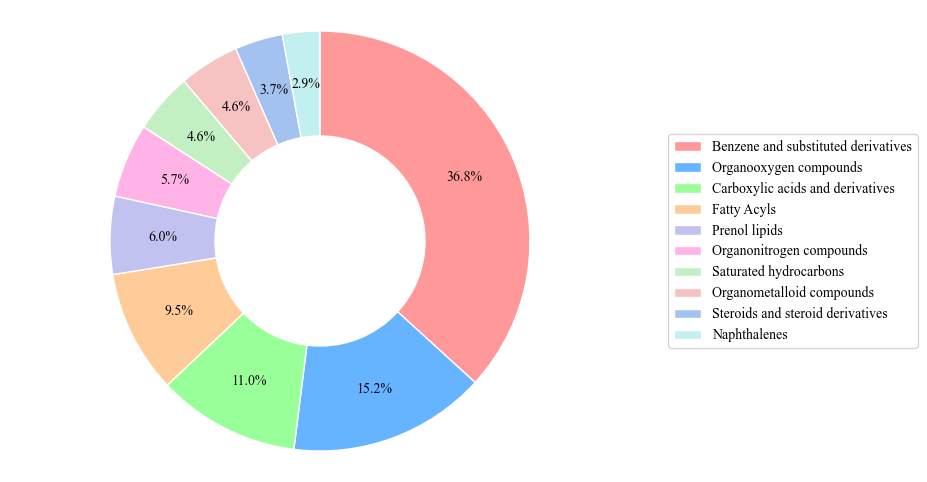

In [7]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import matplotlib.pyplot as plt
from matplotlib import rcParams
from collections import Counter
import pandas as pd

# Set font to Times New Roman for academic paper
rcParams['font.family'] = 'Times New Roman'

# 1. File path
file_path = 'data/nist23_data/test23/test_smiles_with_classification_20260504_233859.csv'

# 2. Read CSV and drop duplicate molecules
df = pd.read_csv(file_path)

# 核心新增：基于 smiles 列去重，确保每个分子只被统计一次
df = df.drop_duplicates(subset=['smiles'])
print(f"Total unique molecules: {len(df)}")

categories = [str(x) for x in df['class']]

# Filter out 'Unclassified' (case-insensitive)
valid_categories = [x for x in categories if x.lower() != 'unclassified']

result = Counter(valid_categories)
print("Classification details (excluding Unclassified):", result)

# 3. Extract the top 10 most common valid classes
top_10 = dict(result.most_common(10))
teacher = list(top_10.keys())
num = list(top_10.values())

# 4. Create and plot the donut pie chart
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0','#ffb3e6', '#c2f0c2', '#f6c2c2', '#a3c2f0', '#c2f0f0']

ax.pie(
    num, 
    autopct=lambda p: '{:.1f}%'.format(p), 
    startangle=90,
    counterclock=False, 
    colors=colors, 
    pctdistance=0.75, 
    wedgeprops=dict(width=0.5, edgecolor='w')
)

# Ensure pie is drawn as a circle
ax.axis('equal')  

# Show legend on the right without overlapping the chart
plt.legend(teacher, loc='center left', bbox_to_anchor=(1.05, 0.5))

plt.savefig('nist23smiles_classyfire_pie.png', dpi=300, bbox_inches='tight') 
plt.show()

# 2. Gen_10 data visaulizer

['CCCCCCOc1ccc(OCCCCCC)cc1' 'COc1cc(Br)cc(OC)c1' 'COC(=O)CCCCCBr'
 'COc1c(Br)cccc1C(C)=O' 'CC(C)(C)c1cc(Br)cc(Br)c1'
 'Brc1ccc(-c2ccc(Br)cn2)nc1' 'COc1cc(-c2c(OC)cccc2OC)cc(OC)c1OC'
 'CC(C)(C)c1cc(C=O)c(O)c(C=O)c1'
 'c1cc(-c2cc(-c3ccncc3)nc(-c3ccncc3)c2)ccn1'
 'BrCCCCCCCCCCCCOc1cc(Br)cc(Br)c1']


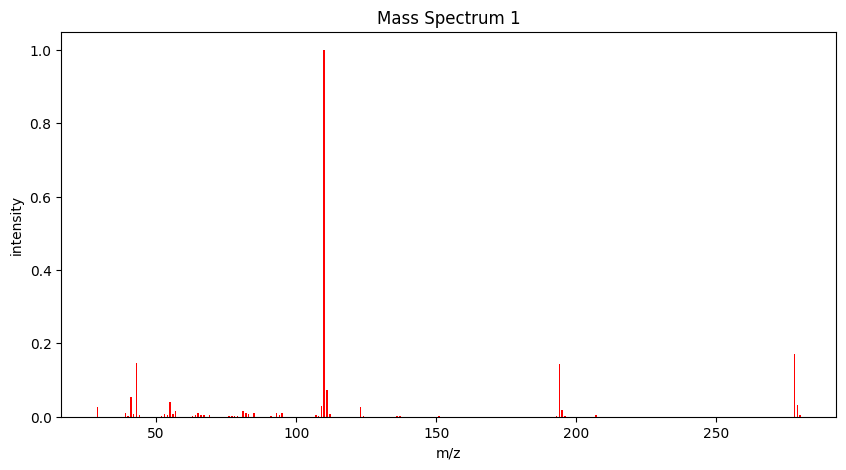

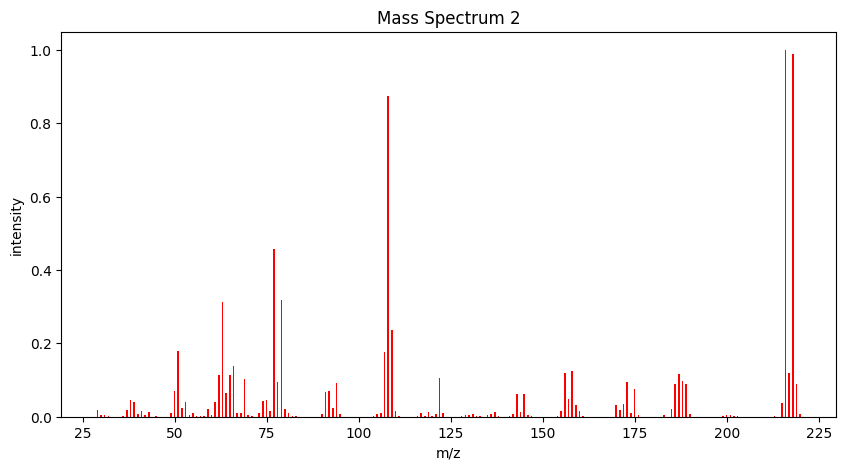

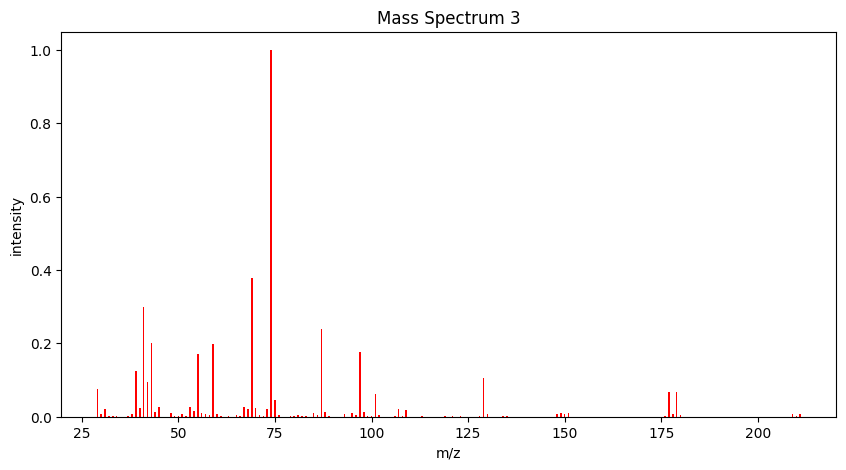

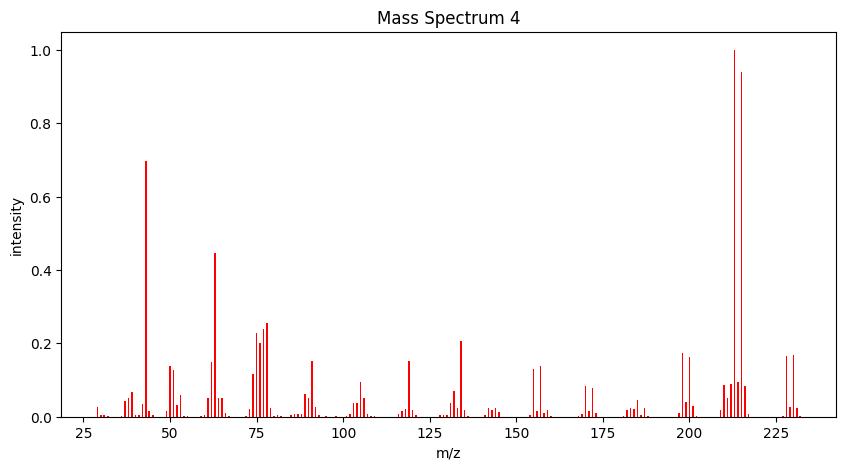

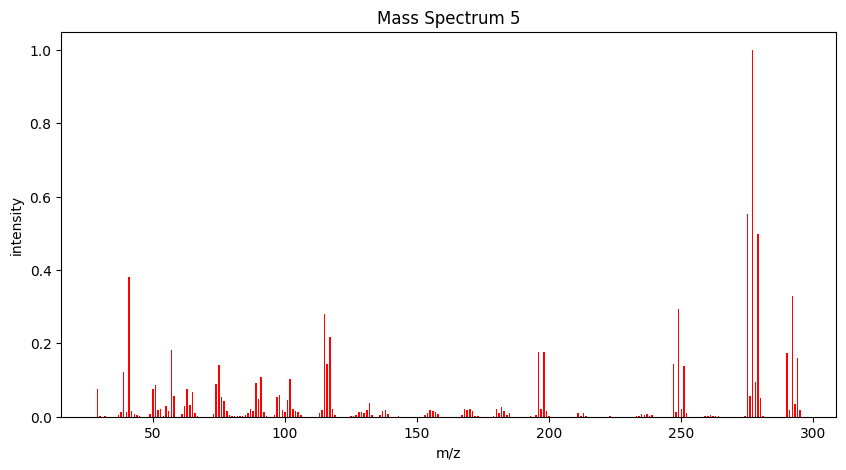

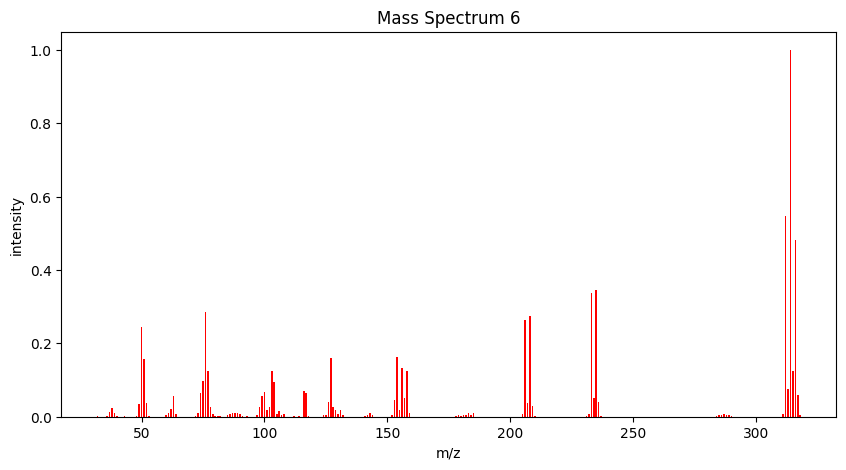

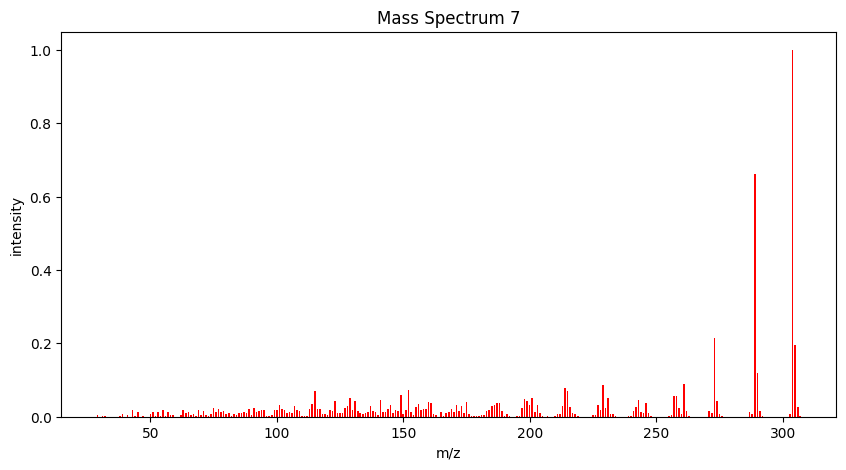

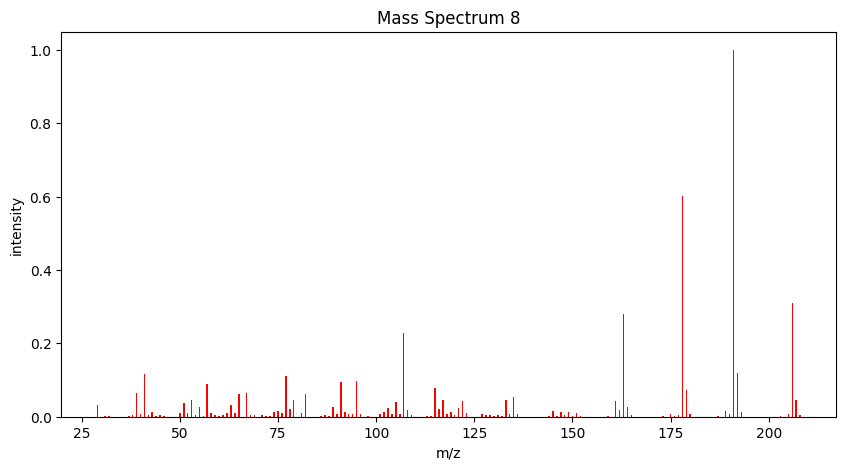

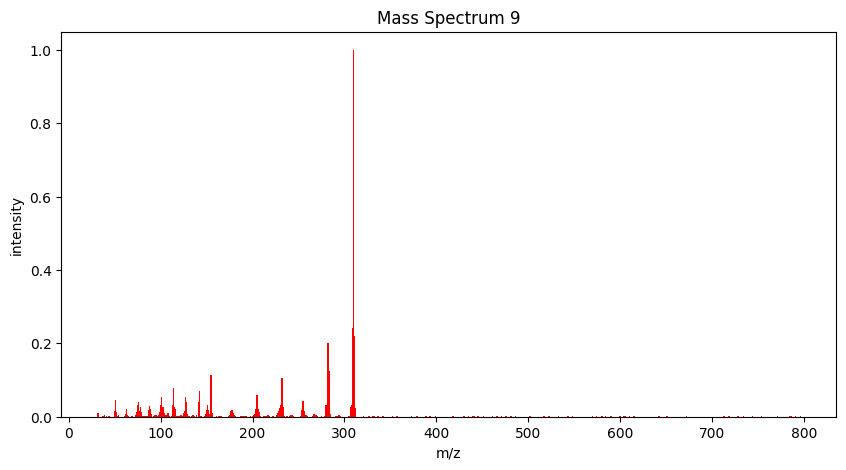

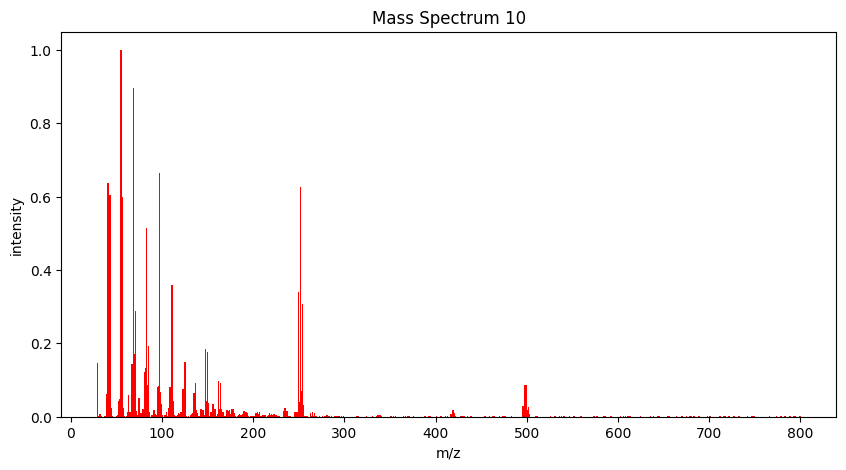

In [42]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analyzer.core import plot_ms_spectrum 

df = pd.read_csv("data/External_Test_Set/Gen_10/10.csv")
SMILES = df["smiles"].values
print(SMILES)
EIMS = df["spectra"].values
plot_ms_spectrum(EIMS, save_dir=None)

# 3. Xianglansu data analyzer

In [2]:
import os, warnings
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import torch
import numpy as np
import matplotlib.pyplot as plt
from utils.NetCDF import data_load

# ================= Setup & Config =================
filename = 'data/External_Test_Set/xianglansu/250106-奶粉-香兰素.CDF'

# ================= Data Loading & Processing =================
print(f"Loading data from: {filename}")
# Load raw data
intensities, mz_values, retention_times = data_load(filename)
num_scans, num_mz = intensities.shape

# Stack M/Z and Intensity into (Scans, M/Z bins, 2)
# Last dim: [mz, intensity]
set1_mass_data = np.dstack((np.tile(mz_values, (num_scans, 1)), intensities))

# ================= Statistics & Validation =================
avg_interval = np.mean(np.diff(retention_times))
nan_status = "Passed (No NaNs)" if not np.isnan(set1_mass_data).any() else f"Found {np.isnan(set1_mass_data).sum()} NaNs"

print("-" * 40)
print(f"Data Summary for: {os.path.basename(filename)}")
print(f"  Dimensions : {num_scans} scans x {num_mz} m/z bins")
print(f"  Time Range : {retention_times.min():.2f} - {retention_times.max():.2f} min")
print(f"  Integrity  : {nan_status}")
print(f"  Scan Freq  : {1/(avg_interval*60):.2f} Hz (Interval: {avg_interval*60:.2f}s)")
print(f"  Data Shape : {set1_mass_data.shape} (Scans, MZ, 2)")
print("-" * 40)

Loading data from: data/External_Test_Set/xianglansu/250106-奶粉-香兰素.CDF
----------------------------------------
Data Summary for: 250106-奶粉-香兰素.CDF
  Dimensions : 8400 scans x 772 m/z bins
  Time Range : 0.00 - 28.00 min
  Integrity  : Passed (No NaNs)
  Scan Freq  : 5.00 Hz (Interval: 0.20s)
  Data Shape : (8400, 772, 2) (Scans, MZ, 2)
----------------------------------------
----------------------------------------
Data Summary for: 250106-奶粉-香兰素.CDF
  Dimensions : 8400 scans x 772 m/z bins
  Time Range : 0.00 - 28.00 min
  Integrity  : Passed (No NaNs)
  Scan Freq  : 5.00 Hz (Interval: 0.20s)
  Data Shape : (8400, 772, 2) (Scans, MZ, 2)
----------------------------------------


In [3]:
# ================= 1. Select Data by Retention Time =================
rt_start, rt_end = 14.05, 14.30
mask = (retention_times >= rt_start) & (retention_times <= rt_end)
target_data = set1_mass_data[mask]
target_rt = retention_times[mask]

print(f"Analyzing {len(target_rt)} scans in region: {rt_start:.3f} - {rt_end:.3f} min")

Analyzing 76 scans in region: 14.050 - 14.300 min


## 3.1 MS preprocessed

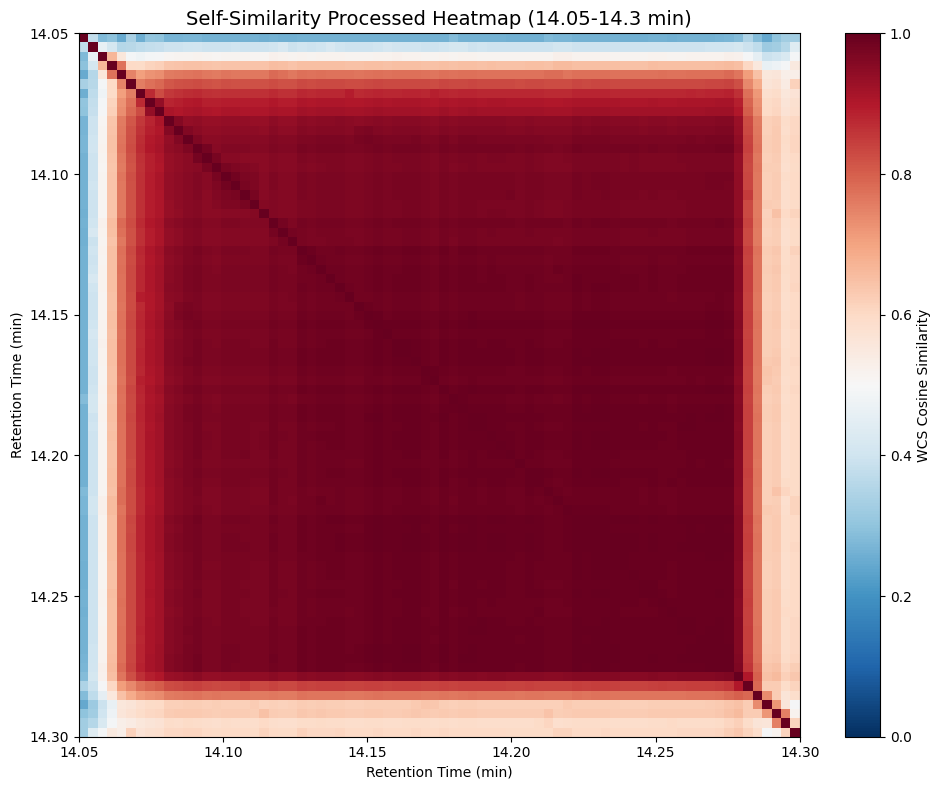

In [7]:
from data_provider.dataset import pre_processing_ms, process_ms_spectra_for_wcs
from analyzer.core import plot_ms_spectrum
import torch
import numpy as np
import matplotlib.pyplot as plt

# ================= 2. Preprocessing =================
real_config = {"dataset_config": {"ms_maxpeaks": 100}}

# List comprehension for cleaner modification
# target_data shape: (Scans, MZ_bins, 2)
processed_pairs = [pre_processing_ms(list(zip(scan[:, 0], scan[:, 1])), real_config) for scan in target_data]

# Unpack results: mz, int, [ignored]
mz_list, int_list, _ = zip(*processed_pairs) # zip(*...) transposes the list of tuples

# Convert to tensor and then numpy for processed data
batch_mz = torch.cat(mz_list, dim=0)
batch_int = torch.cat(int_list, dim=0)
set1_mass_data_processed = np.dstack((batch_mz.cpu().numpy(), batch_int.cpu().numpy()))

# ================= 3. WCS Calculation (Self-Similarity) =================
# Process directly into tensor for similarity calc
wcs_tensor = torch.cat([process_ms_spectra_for_wcs(s, 1000) for s in set1_mass_data_processed], dim=0).view(-1, 1000)
wcs_tensor = torch.nn.functional.normalize(wcs_tensor, p=2, dim=1) # Normalize

wcs_similarity = (wcs_tensor @ wcs_tensor.T).cpu().numpy()
wcs_similarity = np.nan_to_num(wcs_similarity)

# ================= 4. Visualization =================
plt.figure(figsize=(10, 8))
im = plt.imshow(wcs_similarity, aspect='auto', cmap='RdBu_r', interpolation='nearest', 
                vmin=0, vmax=1, origin='upper', 
                extent=[rt_start, rt_end, rt_end, rt_start]) # Set axes directly via extent

plt.colorbar(im, label='WCS Cosine Similarity')
plt.title(f'Self-Similarity Processed Heatmap ({rt_start}-{rt_end} min)', fontsize=14)
plt.xlabel('Retention Time (min)')
plt.ylabel('Retention Time (min)')
plt.tight_layout()
plt.show()

In [8]:
slice_start_rt, slice_end_rt = 14.20, 14.25
# 找到该范围内的所有索引
# np.where 返回的是一个元组，取 [0] 拿到索引数组
indices_in_range = np.where((target_rt >= slice_start_rt) & (target_rt <= slice_end_rt))[0]

print(f"Time Range: {slice_start_rt} - {slice_end_rt} min")
print(f"Total scans found: {len(indices_in_range)}\n")
print("Index\tRetention Time (min)")
print("-" * 30)

# 打印出来供你选择
for idx in indices_in_range:
    print(f"{idx}\t{target_rt[idx]:.4f}")

Time Range: 14.2 - 14.25 min
Total scans found: 16

Index	Retention Time (min)
------------------------------
45	14.2000
46	14.2033
47	14.2067
48	14.2100
49	14.2133
50	14.2167
51	14.2200
52	14.2233
53	14.2267
54	14.2300
55	14.2333
56	14.2367
57	14.2400
58	14.2433
59	14.2467
60	14.2500


Generating reports for indices: [50, 51, 52, 53, 54, 56, 57]



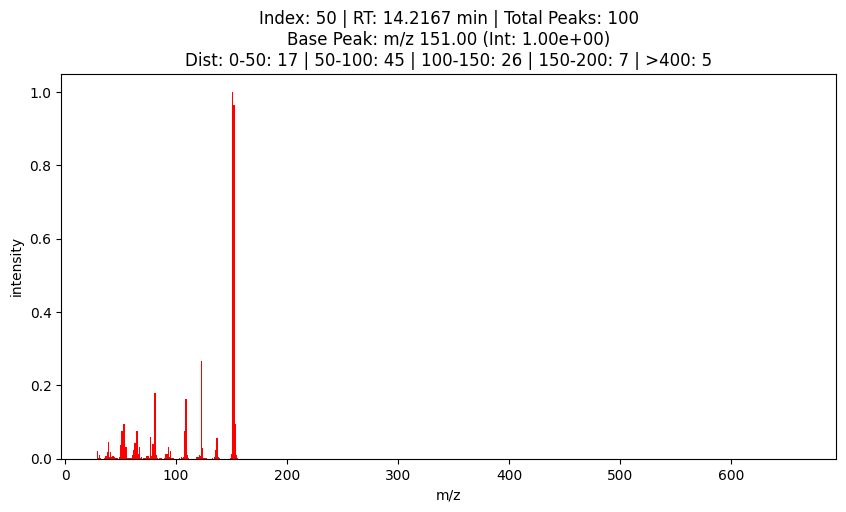

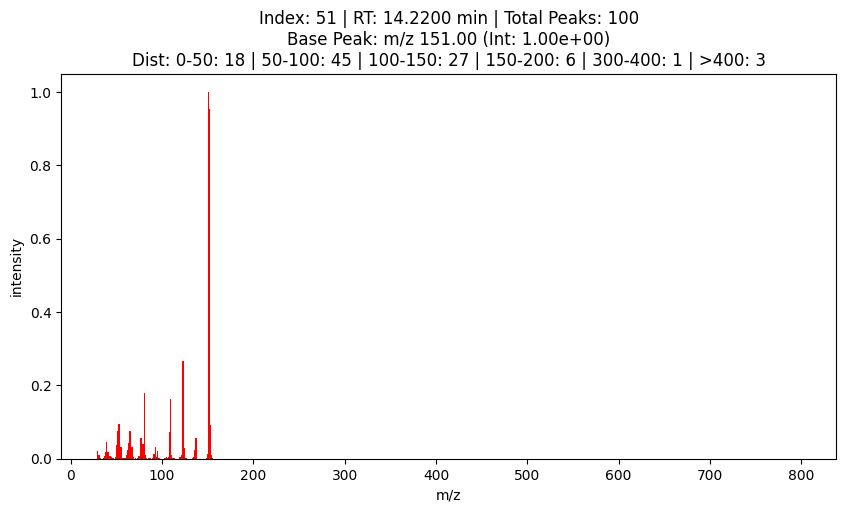

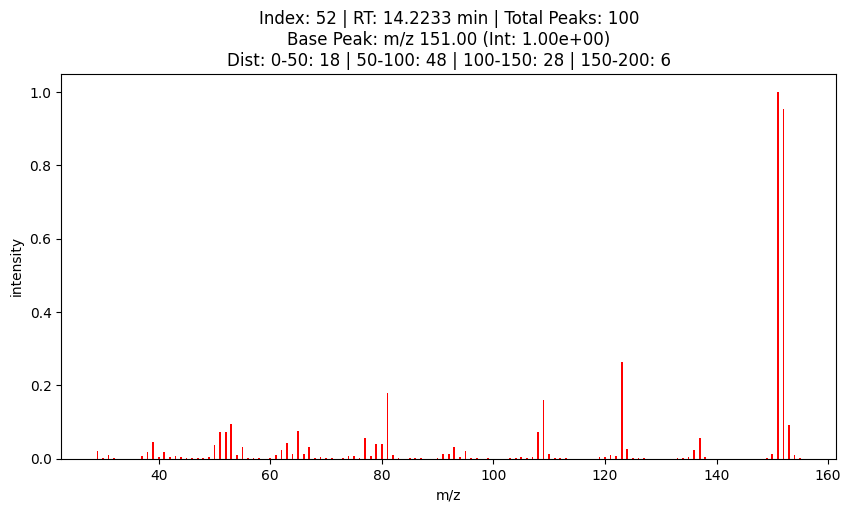

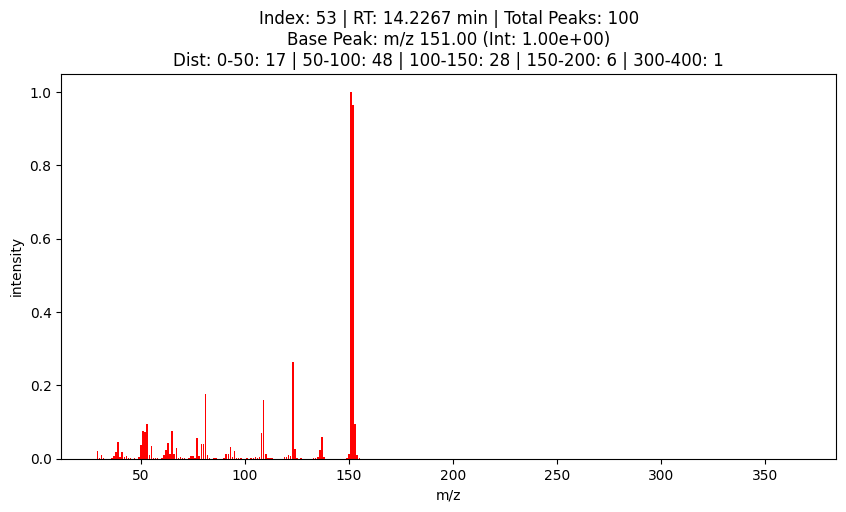

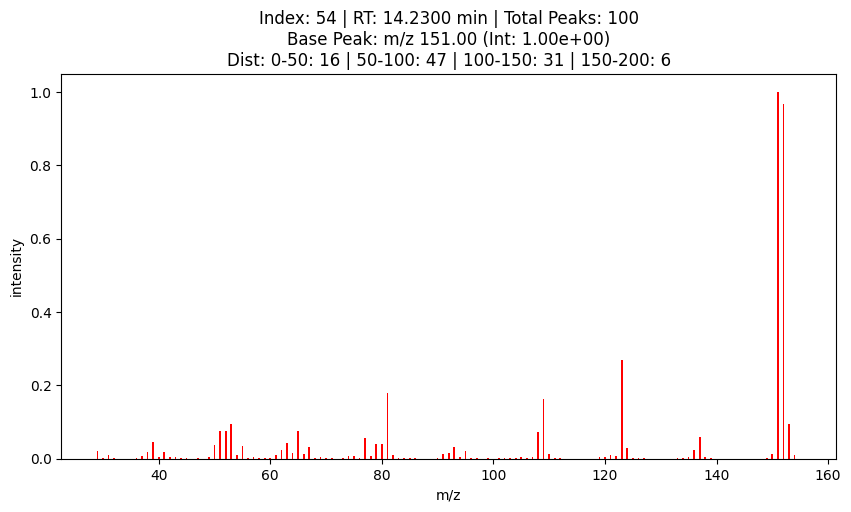

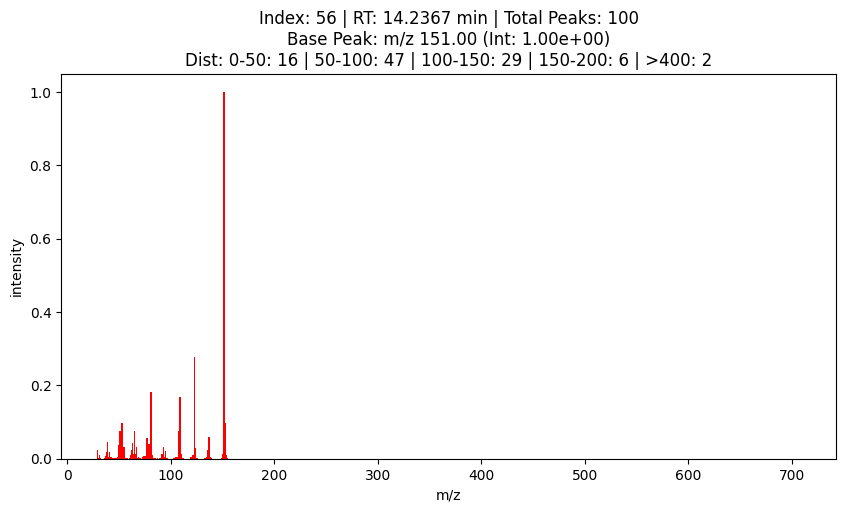

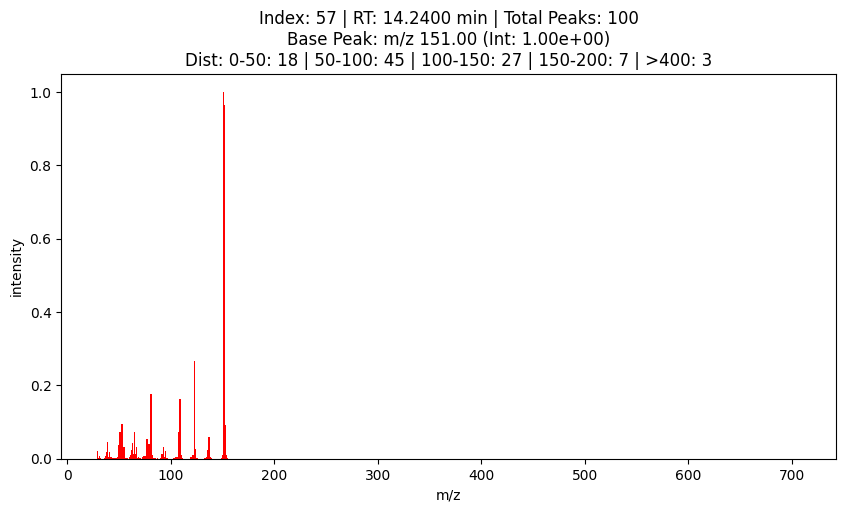

In [9]:
from analyzer.core import plot_ms_spectrum

# ================= 2. Visualization & Statistics for Selected Indices =================
selected_indices = [50, 51, 52, 53, 54, 56, 57] 

EIMS_list_for_plot, titles_list_for_plot = [], []

print(f"Generating reports for indices: {selected_indices}\n")

for idx in selected_indices:
    # Retrieve data
    scan_data = set1_mass_data_processed[idx]
    rt_val = target_rt[idx]
    
    # Filter valid peaks (intensity > 0)
    mz, intensity = scan_data[:, 0], scan_data[:, 1]
    mask = intensity > 0
    mz, intensity = mz[mask], intensity[mask]
    
    # Statistics
    total_peaks = len(mz)
    # Base Peak
    max_idx = np.argmax(intensity)
    base_mz, base_int = mz[max_idx], intensity[max_idx]
    
    # m/z Distribution
    bins = [0, 50, 100, 150, 200, 300, 400, 1000]
    hist, _ = np.histogram(mz, bins=bins)
    # Create concise distribution string e.g., "50-100: 5 | 100-150: 12"
    labels = [f"{bins[i]}-{bins[i+1]}" if i < len(bins)-2 else f">{bins[-2]}" for i in range(len(bins)-1)]
    dist_str = " | ".join([f"{label}: {count}" for label, count in zip(labels, hist) if count > 0])
    
    # Format Title
    title = (f"Index: {idx} | RT: {rt_val:.4f} min | Total Peaks: {total_peaks}\n"
                f"Base Peak: m/z {base_mz:.2f} (Int: {base_int:.2e})\n"
                f"Dist: {dist_str}")

    EIMS_list_for_plot.append(scan_data)
    titles_list_for_plot.append(title)
plot_ms_spectrum(EIMS_list_for_plot, titles=titles_list_for_plot)

## 3.2 MS without preprocessed

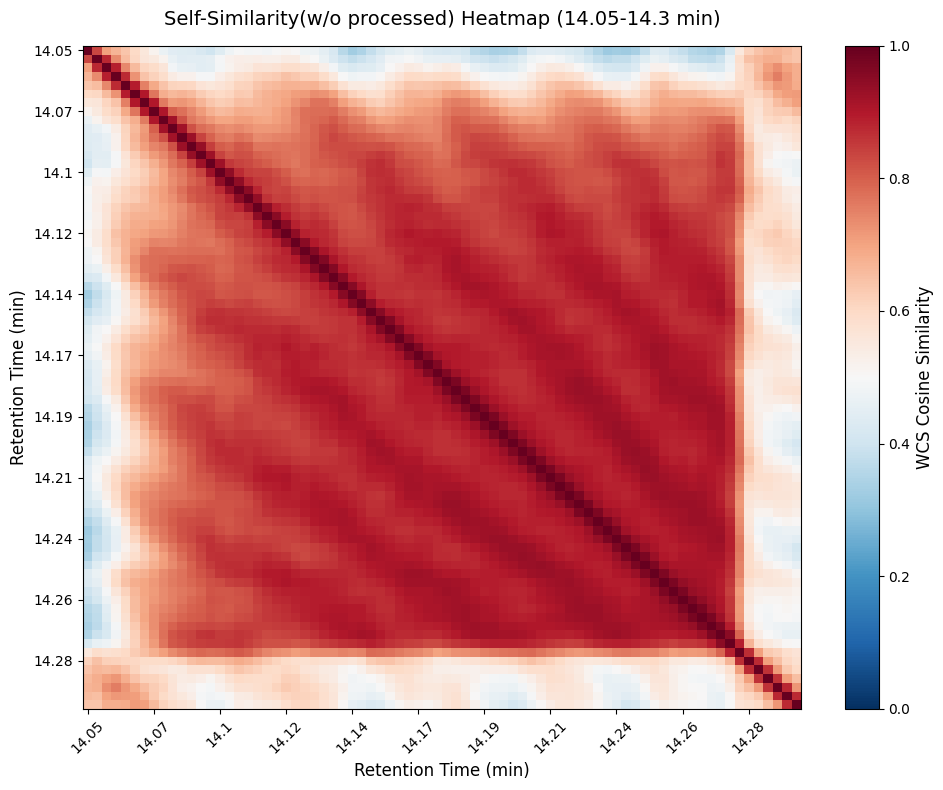

In [11]:
# ================= 3. Calculate WCS (Self-Similarity) =================
# Binning to fixed size (1000) for WCS
set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in target_data], dim=0).reshape(-1, 1000)
set1_ms_tensor /= torch.norm(set1_ms_tensor, dim=-1, keepdim=True)

wcs_similarity = (set1_ms_tensor @ set1_ms_tensor.T).cpu().numpy()
wcs_similarity[np.isnan(wcs_similarity)] = 0

# ================= 4. Visualization: Heatmap =================
plt.figure(figsize=(10, 8))

# Use 'RdBu_r' for Red-Blue heatmap (Red=High similarity, Blue=Low)
im = plt.imshow(wcs_similarity, aspect='auto', cmap='RdBu_r', interpolation='nearest', 
        vmin=0, vmax=1)
        
cbar = plt.colorbar(im)
cbar.set_label('WCS Cosine Similarity', fontsize=12)

plt.title(f'Self-Similarity(w/o processed) Heatmap ({rt_start}-{rt_end} min)', fontsize=14, pad=15)
plt.xlabel('Retention Time (min)', fontsize=12)
plt.ylabel('Retention Time (min)', fontsize=12)

# Ticks
n_ticks = 10
step = max(1, len(target_rt) // n_ticks)
tick_indices = np.arange(0, len(target_rt), step)
tick_labels = np.round(target_rt[tick_indices], 2)

plt.xticks(ticks=tick_indices, labels=tick_labels, rotation=45)
plt.yticks(ticks=tick_indices, labels=tick_labels)

plt.tight_layout()
plt.show()

Generating reports for indices: [50, 51, 52, 53, 54, 56, 57]



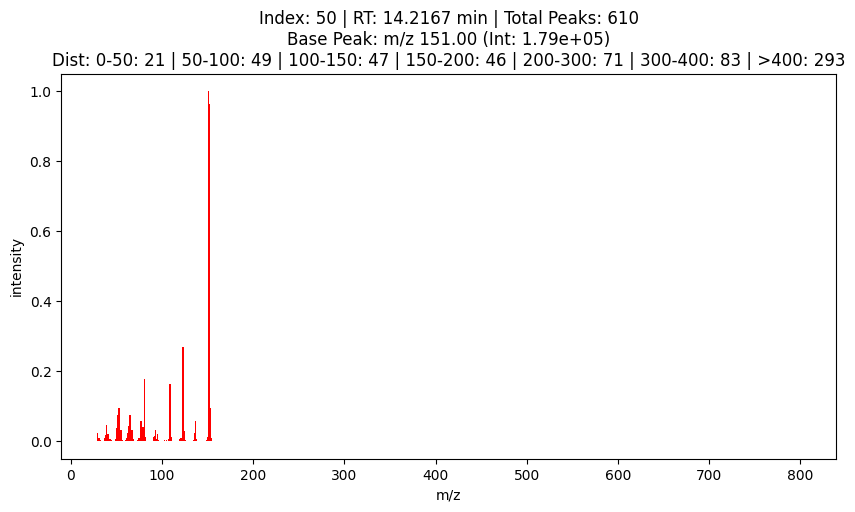

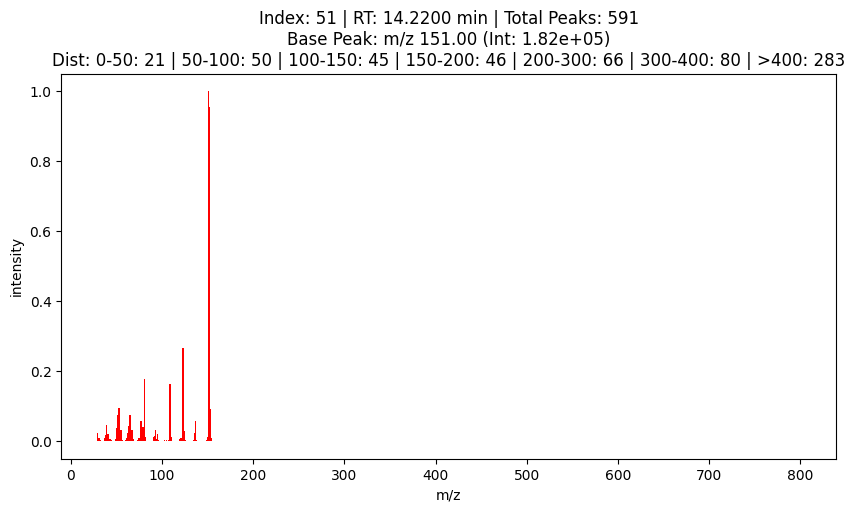

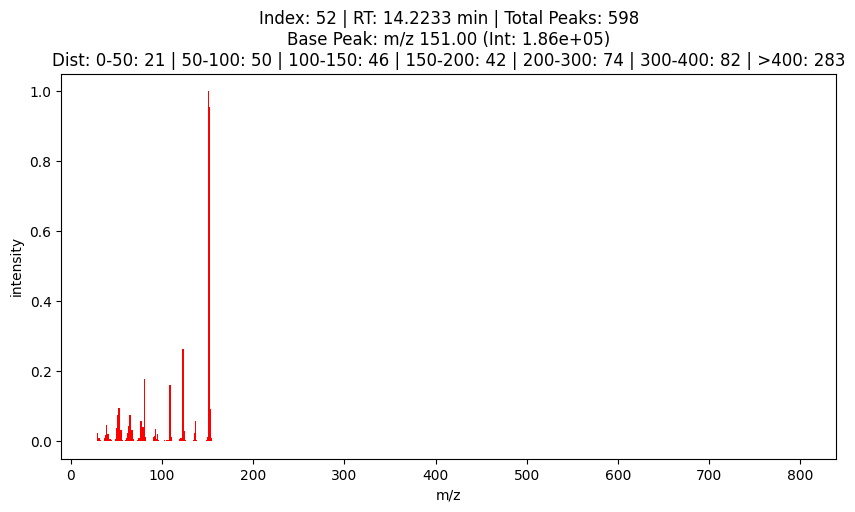

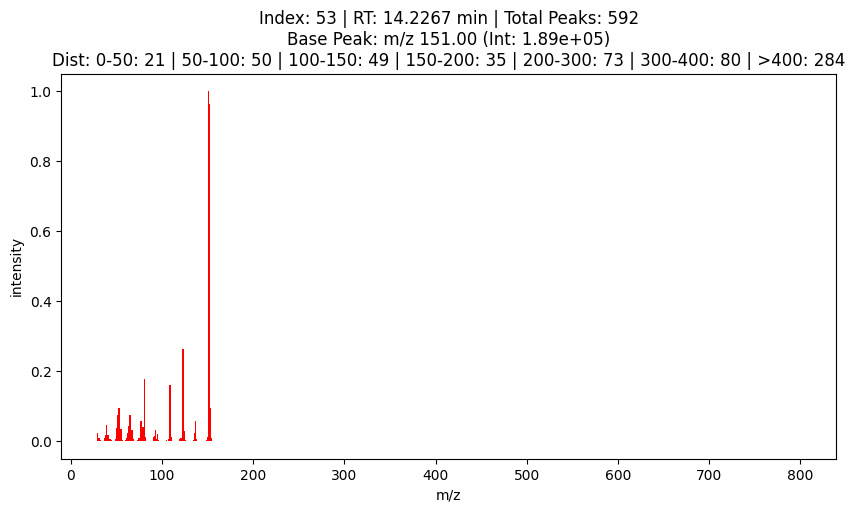

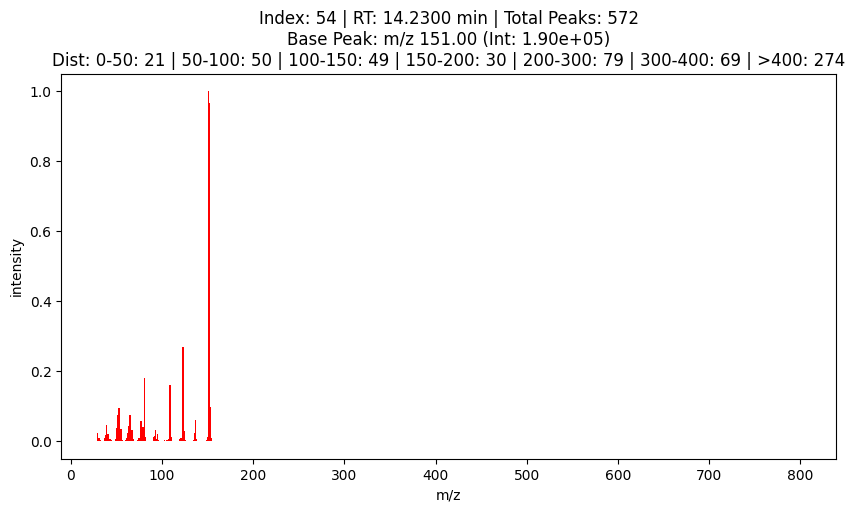

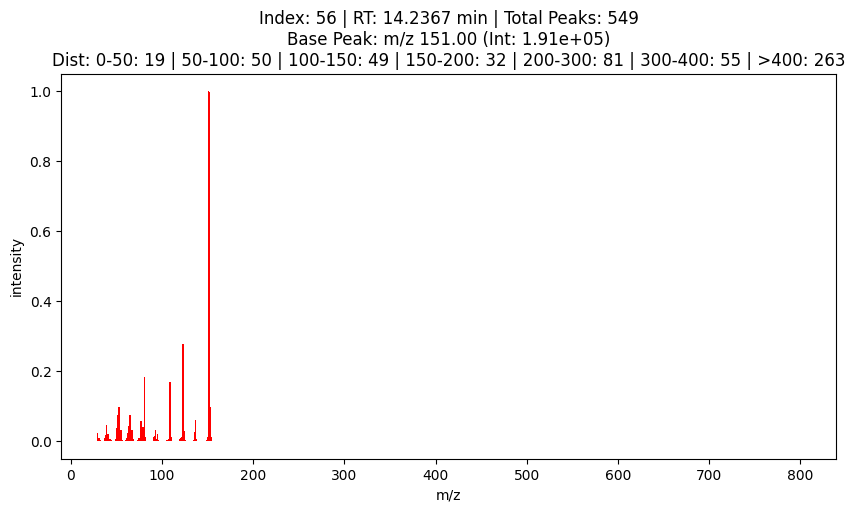

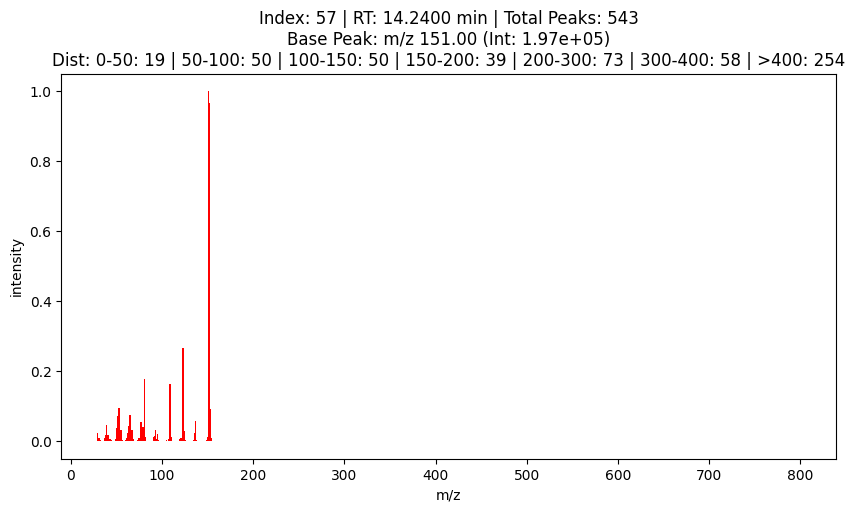

In [13]:
from analyzer.core import plot_ms_spectrum

# ================= 2. Visualization & Statistics for Selected Indices =================
selected_indices = [50, 51, 52, 53, 54, 56, 57] 

EIMS_list_for_plot, titles_list_for_plot = [], []

print(f"Generating reports for indices: {selected_indices}\n")

for idx in selected_indices:
    # Retrieve data
    scan_data = target_data[idx]
    rt_val = target_rt[idx]
    
    # Filter valid peaks (intensity > 0)
    mz, intensity = scan_data[:, 0], scan_data[:, 1]
    mask = intensity > 0
    mz, intensity = mz[mask], intensity[mask]
    
    # Statistics
    total_peaks = len(mz)
    # Base Peak
    max_idx = np.argmax(intensity)
    base_mz, base_int = mz[max_idx], intensity[max_idx]
    
    # m/z Distribution
    bins = [0, 50, 100, 150, 200, 300, 400, 1000]
    hist, _ = np.histogram(mz, bins=bins)
    # Create concise distribution string e.g., "50-100: 5 | 100-150: 12"
    labels = [f"{bins[i]}-{bins[i+1]}" if i < len(bins)-2 else f">{bins[-2]}" for i in range(len(bins)-1)]
    dist_str = " | ".join([f"{label}: {count}" for label, count in zip(labels, hist) if count > 0])
    
    # Format Title
    title = (f"Index: {idx} | RT: {rt_val:.4f} min | Total Peaks: {total_peaks}\n"
                f"Base Peak: m/z {base_mz:.2f} (Int: {base_int:.2e})\n"
                f"Dist: {dist_str}")

    EIMS_list_for_plot.append(scan_data)
    titles_list_for_plot.append(title)
plot_ms_spectrum(EIMS_list_for_plot, titles=titles_list_for_plot)

# 4. Molecular Vector Arithmetic: Analogy Search

## 4.1 Presence vs. Absence of Methoxy Group

Searching:  10%|█         | 1170/11443 [00:00<00:00, 16584.10it/s]


=== Pair 1 ===
With Group (-OCH3): COC(=O)C(F)(F)C(F)(F)C(F)(F)F | ID: 460752
Without Group     : O=CC(F)(F)C(F)(F)C(F)(F)F | ID: 35037


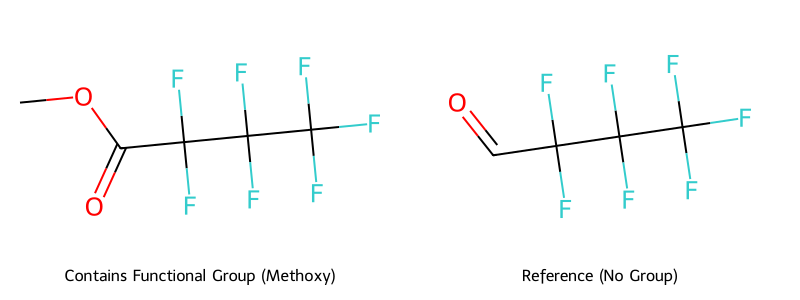


=== Pair 2 ===
With Group (-OCH3): COCCN | ID: 44280
Without Group     : CCN | ID: 228576


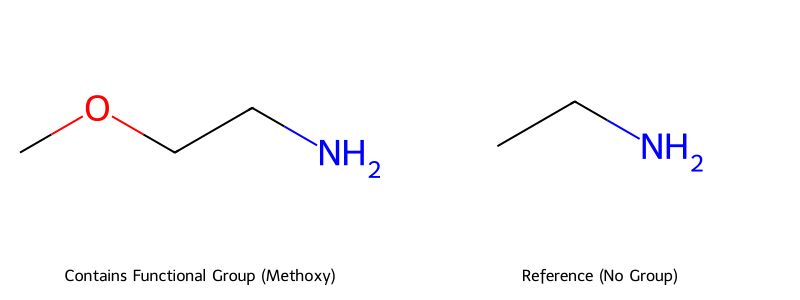


=== Pair 3 ===
With Group (-OCH3): COC(=O)CC(C)CCC=C(C)C | ID: 544504
Without Group     : CC(C)=CCCC(C)CC=O | ID: 43951


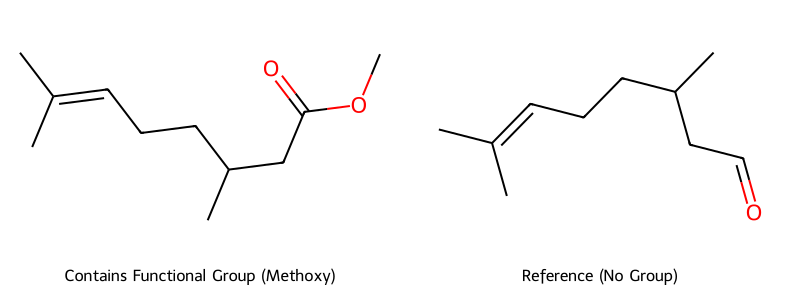


=== Pair 4 ===
With Group (-OCH3): C=C(C)OC | ID: 233773
Without Group     : C=CC | ID: 61300


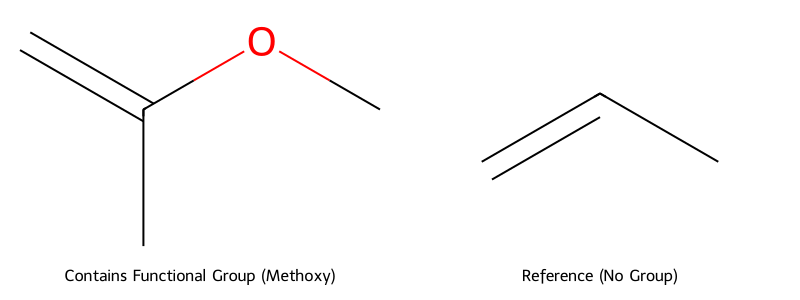


=== Pair 5 ===
With Group (-OCH3): COC(=O)CC(C)O | ID: 194235
Without Group     : CC(O)CC=O | ID: 19522


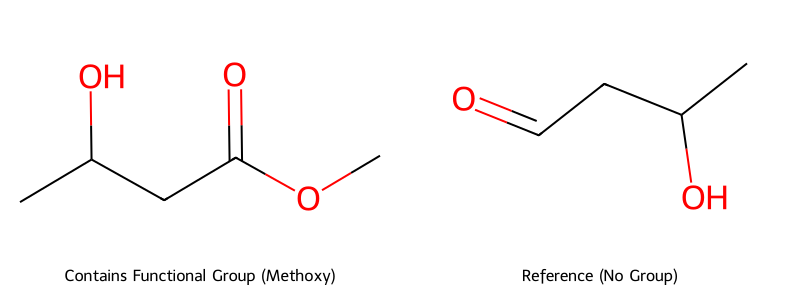


=== Pair 6 ===
With Group (-OCH3): COCCOC(C)=O | ID: 288575
Without Group     : CCOC(C)=O | ID: 228001


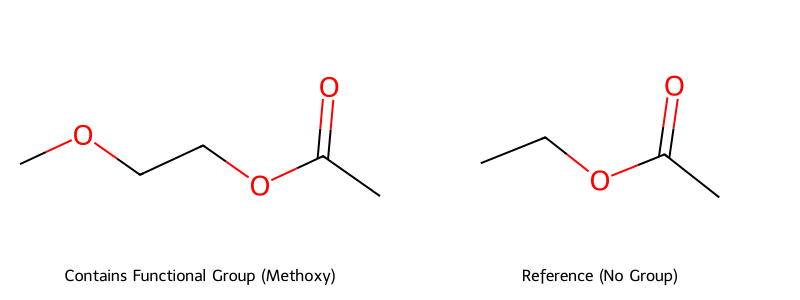


=== Pair 7 ===
With Group (-OCH3): CCCCCC/C=C\CCCCCCCC(=O)OC | ID: 427717
Without Group     : CCCCCC/C=C\CCCCCCCC=O | ID: 291652


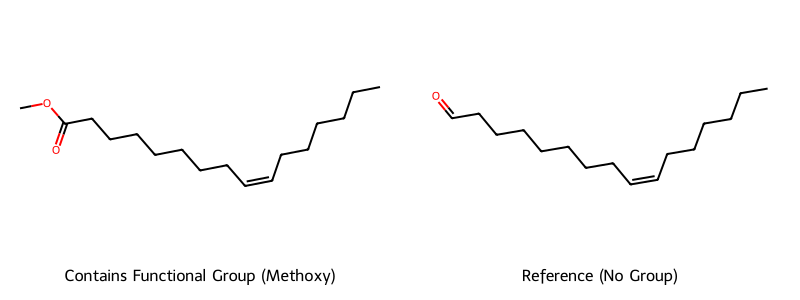


=== Pair 8 ===
With Group (-OCH3): COC(C)(OC)OC | ID: 428399
Without Group     : COC(C)OC | ID: 228234


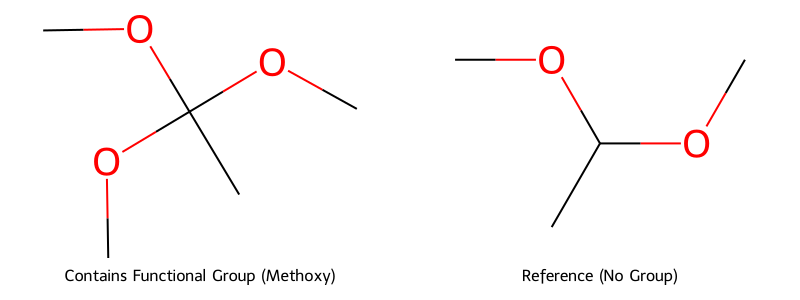


=== Pair 9 ===
With Group (-OCH3): COC(C)(OC)OC | ID: 428399
Without Group     : COC(C)OC | ID: 228234


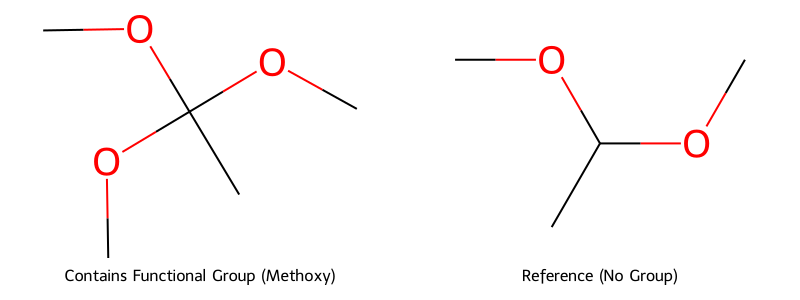


=== Pair 10 ===
With Group (-OCH3): COC(C)(OC)OC | ID: 428399
Without Group     : COC(C)OC | ID: 228234


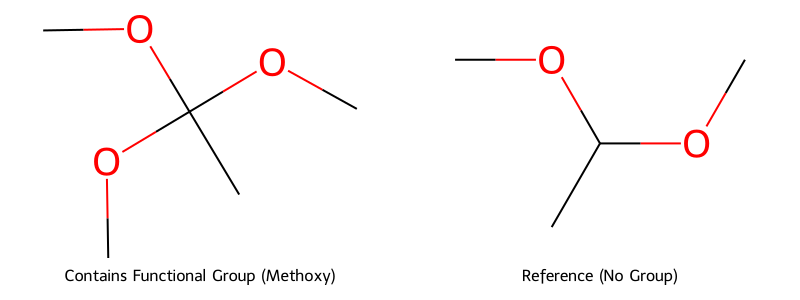

In [ ]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from tqdm import tqdm
from analyzer.core import get_data_and_features, get_cos_distance, get_topk_acc, find_functional_group_pairs

# ================= Execution =================
target_json = "data/nist23_data/test23/test.json"
# Example: Remove Methoxy (-OCH3) group
# Matches: [Scaffold Carbon] - [Oxygen] - [Methyl Carbon] -> [Scaffold Carbon]
transform_remove_Methoxy = '[C:1][O][C;H3]>>[C:1]' 
pairs = find_functional_group_pairs(target_json, transform_remove_Methoxy, max_pairs=10)

# ================= Visualization =================
if not pairs:
    print("No pairs found matching the criteria.")
else:
    for i, pair in enumerate(pairs):
        mol_grp = pair['with_group']
        mol_no_grp = pair['without_group']
        
        print(f"\n=== Pair {i+1} ===")
        # Use .get() to avoid KeyError if 'nist' id is missing
        print(f"With Group (-OCH3): {mol_grp['smiles']} | ID: {mol_grp.get('nist', 'N/A')}")
        print(f"Without Group     : {mol_no_grp['smiles']} | ID: {mol_no_grp.get('nist', 'N/A')}")
        
        mols = [Chem.MolFromSmiles(mol_grp['smiles']), Chem.MolFromSmiles(mol_no_grp['smiles'])]
        img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(400, 300), 
                                   legends=["Contains Functional Group (Methoxy)", "Reference (No Group)"])
        display(img)

Indexing dataset...


Indexing: 100%|██████████| 20916/20916 [00:02<00:00, 8332.50it/s]


Searching for pairs using transformation: [*:1][Cl]>>[*:1][H]
Filter pattern (stripped maps): [*][Cl]
Step 1: identifying candidate molecules containing the functional group...


Filtering Candidates: 100%|██████████| 11443/11443 [00:00<00:00, 12547.64it/s]


Found 1348 potential source molecules.
Step 2: Generating products and searching for matches...


Finding Pairs:   0%|          | 0/1348 [00:00<?, ?it/s]


[MATCH FOUND] Pair 1
Source (ID 60302): COc1cc(Cl)c(O)cc1Cl
Target (ID 319464): COc1ccc(O)c(Cl)c1


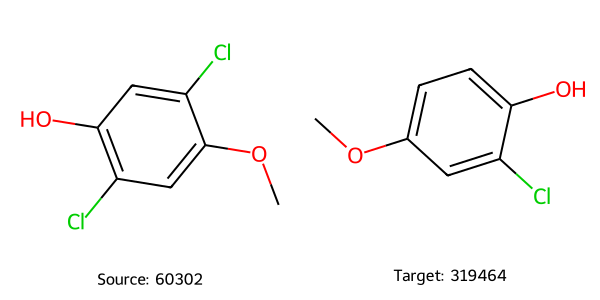


[MATCH FOUND] Pair 2
Source (ID 59499): O=C1CCC(=O)N1Cl
Target (ID 220883): O=C1CCC(=O)N1


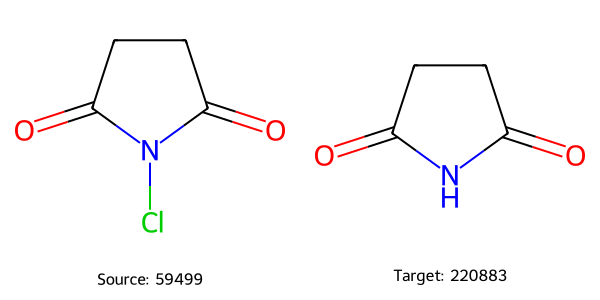


[MATCH FOUND] Pair 3
Source (ID 5396): CCOC(=O)C(Cl)Cl
Target (ID 107469): CCOC(=O)CCl


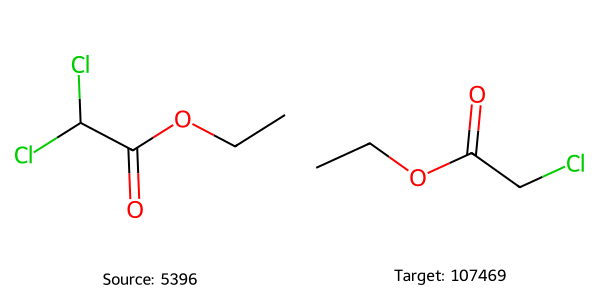


[MATCH FOUND] Pair 4
Source (ID 72929): CCN(CC)C(=O)Cl
Target (ID 19872): CCN(C=O)CC


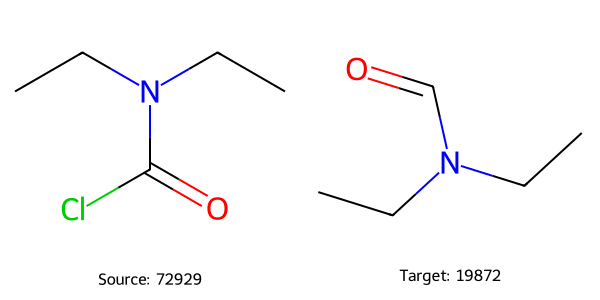


[MATCH FOUND] Pair 5
Source (ID 107469): CCOC(=O)CCl
Target (ID 228001): CCOC(C)=O


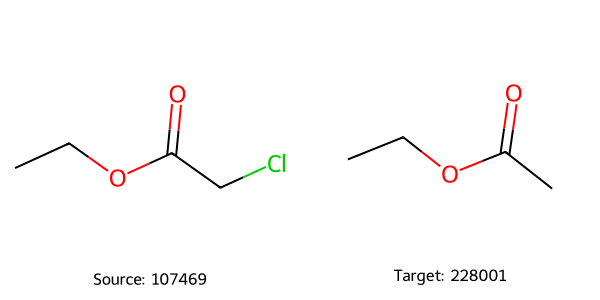


[MATCH FOUND] Pair 6
Source (ID 368606): CCOP(=O)(Cl)OCC
Target (ID 163654): CCO[PH](=O)OCC


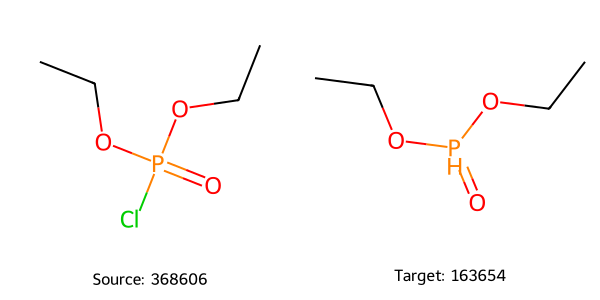


[MATCH FOUND] Pair 7
Source (ID 108054): NCCc1ccc(Cl)cc1
Target (ID 42275): NCCc1ccccc1


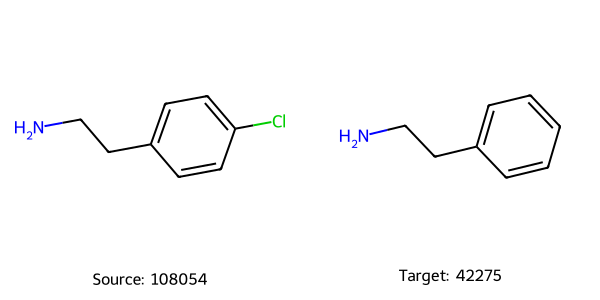


[MATCH FOUND] Pair 8
Source (ID 52462): N#Cc1c(Cl)cccc1[N+](=O)[O-]
Target (ID 52468): N#Cc1ccccc1[N+](=O)[O-]


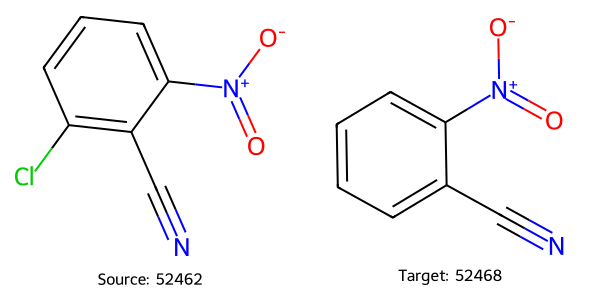


[MATCH FOUND] Pair 9
Source (ID 125104): O=[N+]([O-])c1ccc(Cl)cc1C(F)(F)F
Target (ID 290773): O=[N+]([O-])c1ccccc1C(F)(F)F


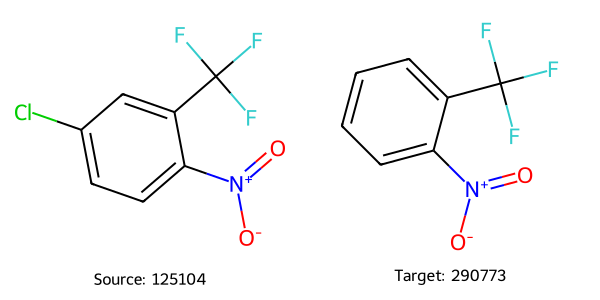


[MATCH FOUND] Pair 10
Source (ID 69655): O=[N+]([O-])c1ccc(Cl)c([N+](=O)[O-])c1
Target (ID 118570): O=[N+]([O-])c1cccc([N+](=O)[O-])c1


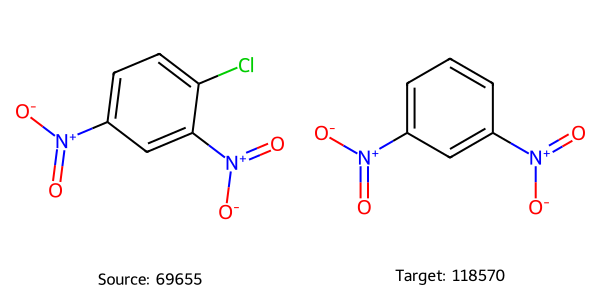

Finding Pairs:   2%|▏         | 22/1348 [00:00<00:06, 212.57it/s]

Reached max_pairs limit (10). Stopping.


In [2]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
from analyzer.core import find_and_visualize_pairs

# 查找氯原子变氢原子的分子对
# Transformation: Candidate (with Cl) -> Target (with H)
transform_remove_Chlorine = '[*:1][Cl]>>[*:1][H]' 
find_and_visualize_pairs("data/nist23_data/test23/test.json", transform_remove_Chlorine, max_pairs=10)

Searching for Methyl Ester -> Acid pairs...
Indexing dataset...


Indexing: 100%|██████████| 20916/20916 [00:02<00:00, 8466.65it/s]


Searching for pairs using transformation: [*:1][C](=[O:2])[O][C;H3]>>[*:1][C](=[O:2])[O]
Filter pattern (stripped maps): [*][C](=[O])[O][C;H3]
Step 1: identifying candidate molecules containing the functional group...


Filtering Candidates: 100%|██████████| 11443/11443 [00:00<00:00, 12200.20it/s]


Found 509 potential source molecules.
Step 2: Generating products and searching for matches...


Finding Pairs:   0%|          | 0/509 [00:00<?, ?it/s]


[MATCH FOUND] Pair 1
Source (ID 460752): COC(=O)C(F)(F)C(F)(F)C(F)(F)F
Target (ID 463764): O=C(O)C(F)(F)C(F)(F)C(F)(F)F


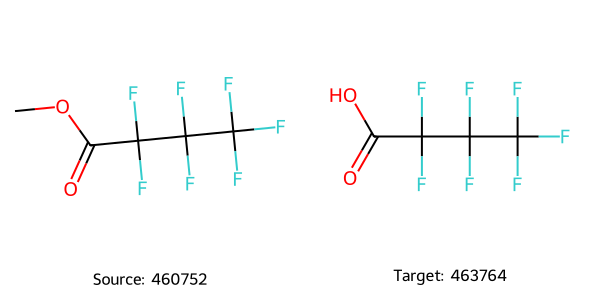


[MATCH FOUND] Pair 2
Source (ID 71100): COC(=O)C(C)Br
Target (ID 118352): CC(Br)C(=O)O


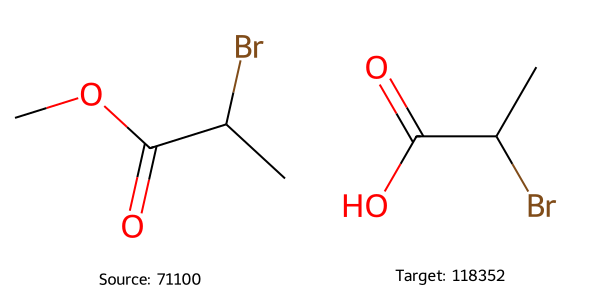


[MATCH FOUND] Pair 3
Source (ID 191131): COC(=O)CO
Target (ID 221232): O=C(O)CO


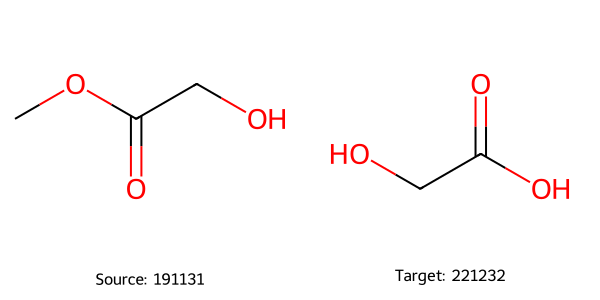


[MATCH FOUND] Pair 4
Source (ID 186558): C=C(CBr)C(=O)OC
Target (ID 265764): C=C(CBr)C(=O)O


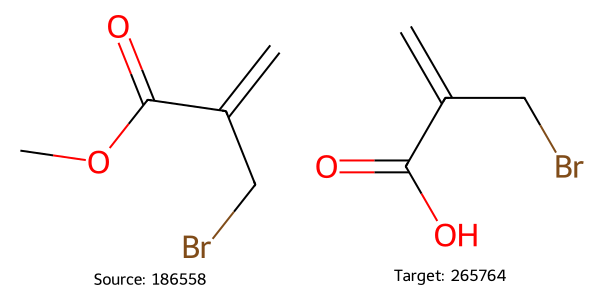


[MATCH FOUND] Pair 5
Source (ID 544504): COC(=O)CC(C)CCC=C(C)C
Target (ID 544502): CC(C)=CCCC(C)CC(=O)O


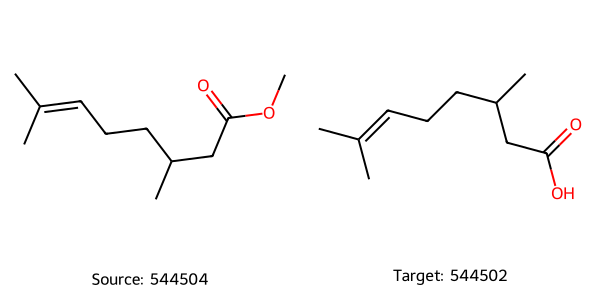


[MATCH FOUND] Pair 6
Source (ID 229193): COC(=O)C(C)=O
Target (ID 558329): CC(=O)C(=O)O


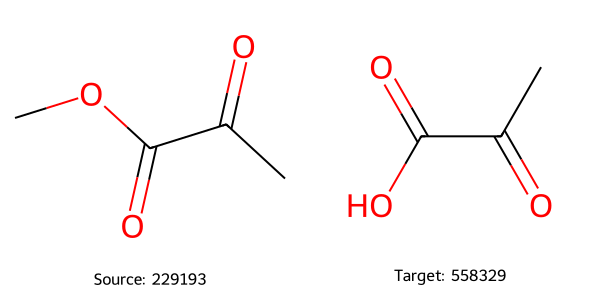


[MATCH FOUND] Pair 7
Source (ID 285380): COC(=O)C(C)C
Target (ID 375975): CC(C)C(=O)O


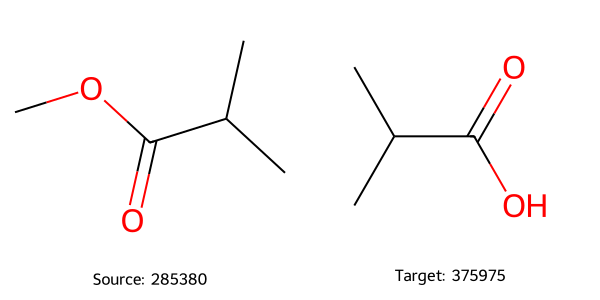


[MATCH FOUND] Pair 8
Source (ID 194235): COC(=O)CC(C)O
Target (ID 1309): CC(O)CC(=O)O


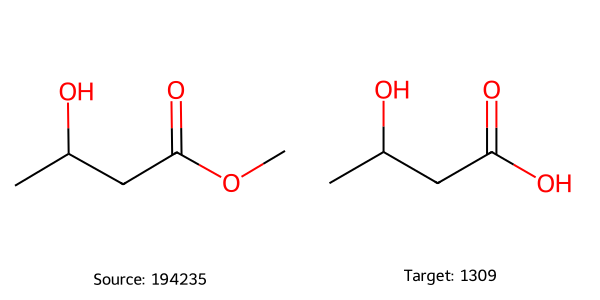

Finding Pairs:   6%|▌         | 31/509 [00:00<00:01, 301.08it/s]


[MATCH FOUND] Pair 9
Source (ID 414916): CCCCCCCCCCCCCCC(O)C(=O)OC
Target (ID 136286): CCCCCCCCCCCCCCC(O)C(=O)O


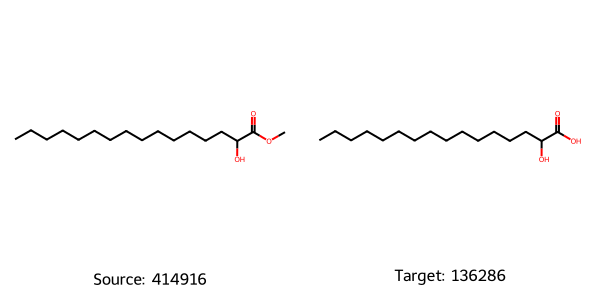


[MATCH FOUND] Pair 10
Source (ID 110111): COC(=O)CCCCC(C)=O
Target (ID 164315): CC(=O)CCCCC(=O)O


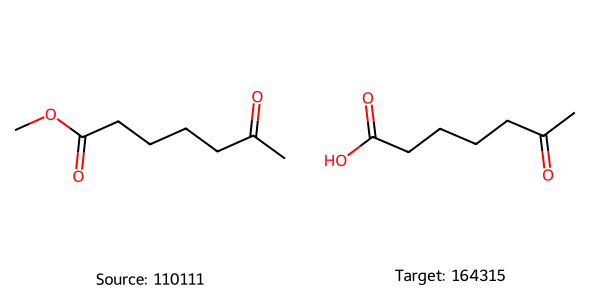

Finding Pairs:   7%|▋         | 37/509 [00:00<00:01, 291.43it/s]

Reached max_pairs limit (10). Stopping.


In [3]:
from analyzer.core import find_and_visualize_pairs

# 查找甲酯变羧酸的分子对
# Methyl Ester to Carboxylic Acid
# Transformation: [*:1]-C(=O)-O-CH3  >>  [*:1]-C(=O)-OH
# SMARTS: [*:1][C](=[O:2])[O][C;H3] >> [*:1][C](=[O:2])[O]
transform_methyl_ester_to_acid = '[*:1][C](=[O:2])[O][C;H3]>>[*:1][C](=[O:2])[O]' 

print(f"Searching for Methyl Ester -> Acid pairs...")
find_and_visualize_pairs("data/nist23_data/test23/test.json", transform_methyl_ester_to_acid, max_pairs=10)

## 4.2 Transformation: Ester to Acid (-CH2)

Loading & Indexing data\nist23_data\test23\test.json...


Indexing SMILES: 100%|██████████| 20916/20916 [00:02<00:00, 8489.46it/s]

Query: ID 424502 | SMILES: COC(=O)c1cccc2ccccc12

[MATCH] Found Target ID: 232430 | SMILES: O=C(O)c1cccc2ccccc12


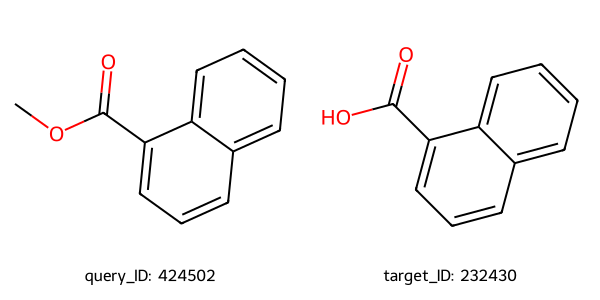

In [4]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from tqdm import tqdm
from analyzer.core import search_pair

# ================= Configuration =================
# Transformation: Ester to Carboxylic Acid
# [*:1] is the Carbon of the Carbonyl group.
# [O:2] is the Oxygen of the Carbonyl group.
# Improved generic pattern:
# [*:1]C(=[O:2])O[#6] >> [*:1]C(=[O:2])O
target_id = 424502
transform_group = "[*:1][C](=[O:2])[O][C;H3]>>[*:1][C](=[O:2])[O]"

# # Transformation: Carboxylic Acid to Aldehyde
# # [*:1] - Carbonyl Carbon - Hydroxyl Oxygen  >>  [*:1] - Carbonyl Carbon (with H)
# # Pattern: [*:1][C](=[O:2])[OH] >> [*:1][C;H1](=[O:2])
# target_id = 232430 
# transform_group = "[*:1][C](=[O:2])[O;H1]>>[*:1][C;H1](=[O:2])"


target_json = r"data\nist23_data\test23\test.json"
print(f"Loading & Indexing {target_json}...")
with open(target_json, 'r') as f:
    data_list = json.load(f)

# Build Lookup Tables
id_map = {str(d.get('nist', '')): d for d in data_list if d.get('nist')}
smi_map = {}
for d in tqdm(data_list, desc="Indexing SMILES"):
    if s := d.get('smiles'):
        if m := Chem.MolFromSmiles(s):
            smi_map[Chem.MolToSmiles(m, isomericSmiles=True)] = d

# Execute
search_pair(target_id, transform_group, smi_map, id_map)

Visualizing 9 candidate pairs...

=== Pair: 428213 vs 428214 ===


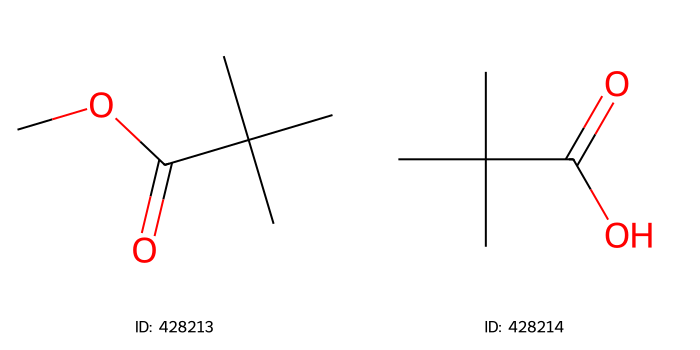

=== Pair: 194235 vs 1309 ===


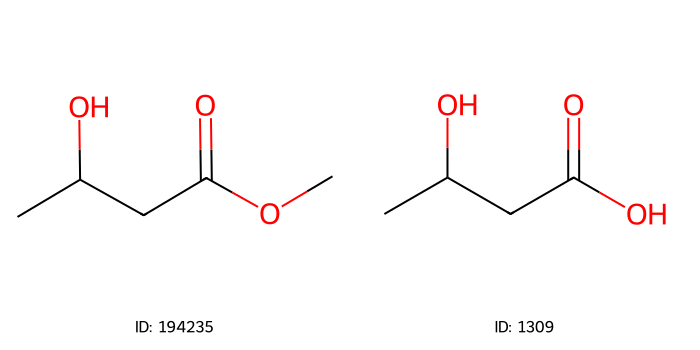

=== Pair: 429178 vs 230359 ===


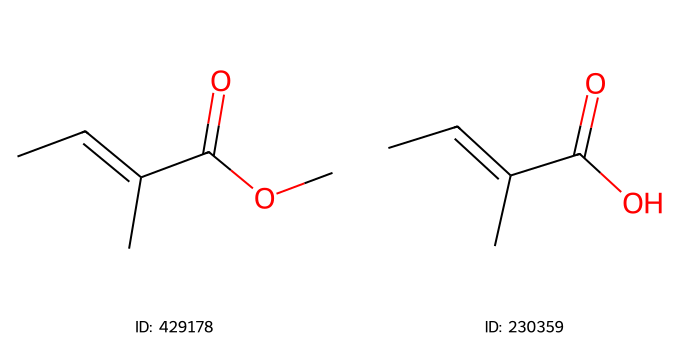

=== Pair: 544504 vs 544502 ===


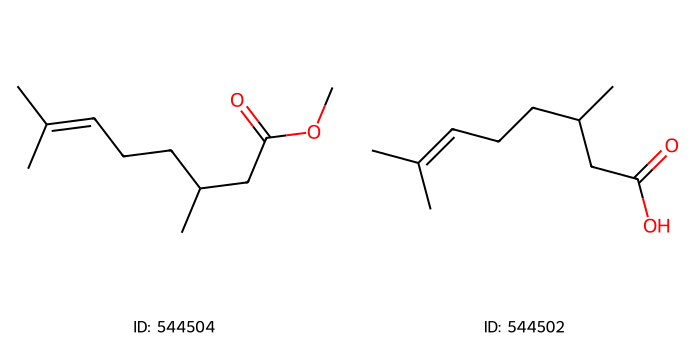

=== Pair: 473834 vs 488292 ===


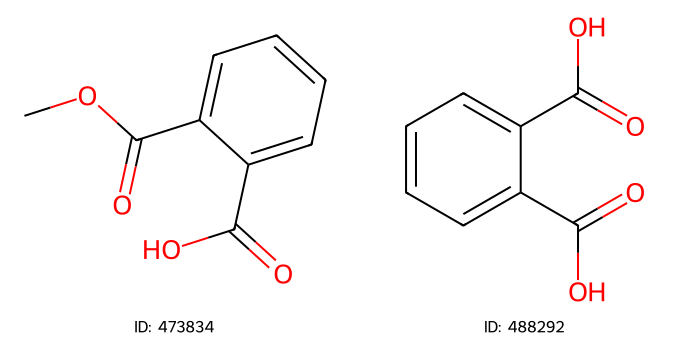

=== Pair: 99162 vs 233344 ===


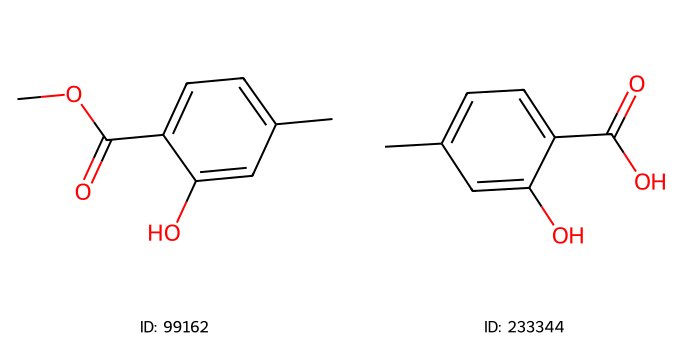

=== Pair: 558144 vs 445072 ===


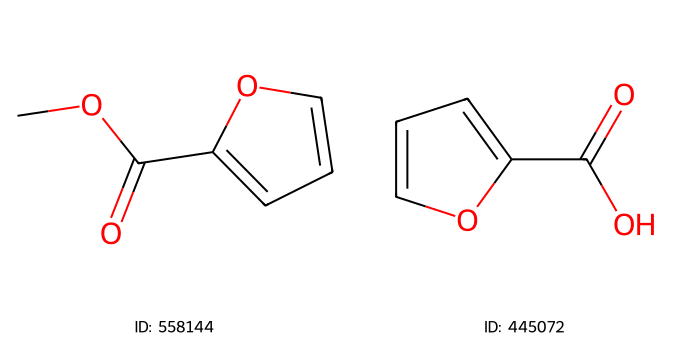

=== Pair: 186733 vs 428618 ===


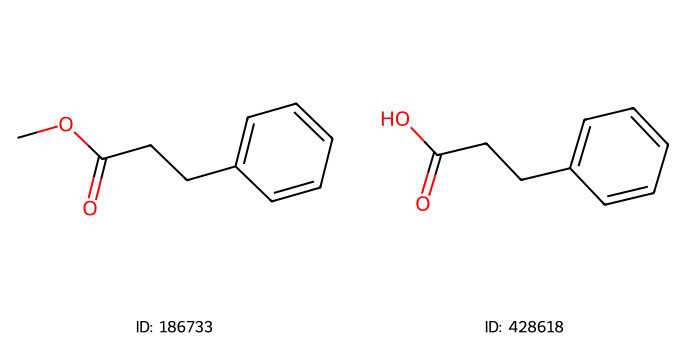

=== Pair: 424502 vs 232430 ===


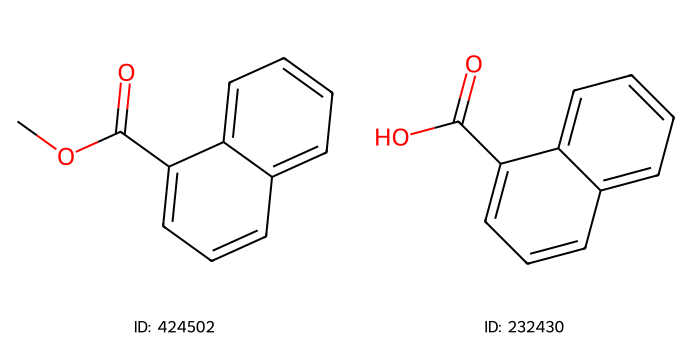

In [6]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

# ================= Configuration =================
candidate_pair_ids = [
    ("428213", "428214"), ("194235", "1309"), ("429178", "230359"), 
    ("544504", "544502"), ("473834", "488292"), ("99162", "233344"), 
    ("558144", "445072"), ("186733", "428618"), ("424502", "232430")
]

target_json = r"data\nist23_data\test23\test.json"
with open(target_json, 'r') as f:
    data_list = json.load(f)

id_to_data = {str(d['nist']): d for d in data_list}

# ================= Visualization =================
print(f"Visualizing {len(candidate_pair_ids)} candidate pairs...\n")

for id_a, id_b in candidate_pair_ids:
    if (data_a := id_to_data.get(str(id_a))) and (data_b := id_to_data.get(str(id_b))):
        mols = [Chem.MolFromSmiles(data_a['smiles']), Chem.MolFromSmiles(data_b['smiles'])]
        print(f"=== Pair: {id_a} vs {id_b} ===")
        display(Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(350, 350), 
                                     legends=[f"ID: {id_a}", f"ID: {id_b}"]))
    else:
        print(f"Skipping Pair {id_a}-{id_b}: Data not found.")

Total molecules to plot: 7


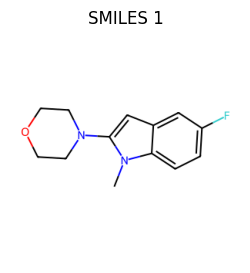

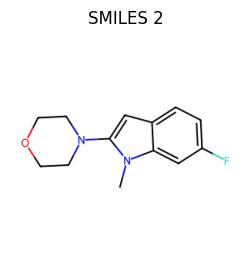

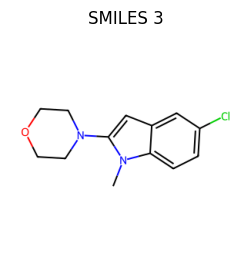

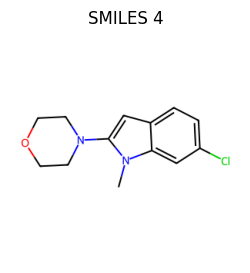

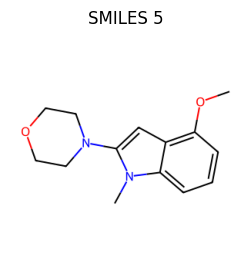

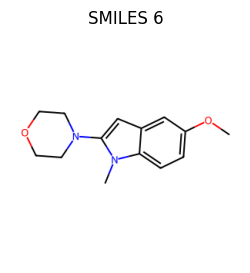

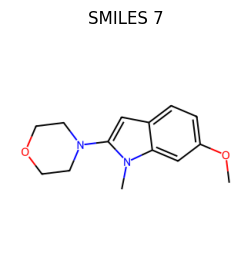

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
    
import pandas as pd
from analyzer.core import plot_mol_structure

# 1. 设置文件路径
csv_path = "data/External_Test_Set/Iso_7/smiles_peak_data.csv"
save_directory = "data/External_Test_Set/Iso_7/mol_structures" # 如果不需要保存文件可以设为 None

# 2. 读取 CSV 文件
df = pd.read_csv(csv_path)

# 假设 SMILES 在第一列（或者你也可以用 df['smiles'].tolist() 如果列名是 smiles）
smiles_list = df.iloc[:, 0].tolist()
print(f"Total molecules to plot: {len(smiles_list)}")

# 3. 绘制并保存分子图
plot_mol_structure(smiles_list)

In [ ]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analyzer.core import plot_ms_spectrum 

df = pd.read_csv("data/External_Test_Set/Gen_10/10.csv")
SMILES = df["smiles"].values
print(SMILES)
EIMS = df["spectra"].values
plot_ms_spectrum(EIMS, save_dir=None)

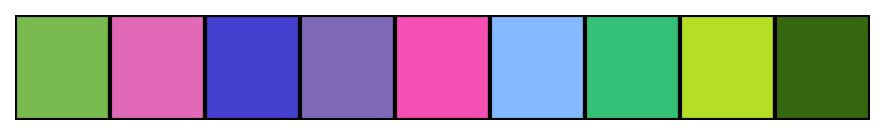

✅ 已生成第 1 张向量图


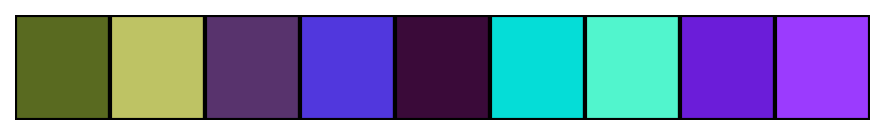

✅ 已生成第 2 张向量图


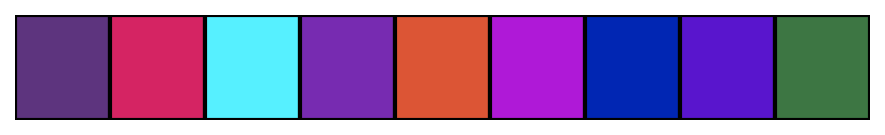

✅ 已生成第 3 张向量图


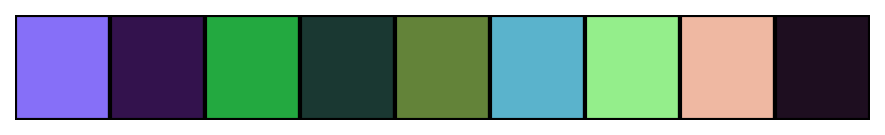

✅ 已生成第 4 张向量图


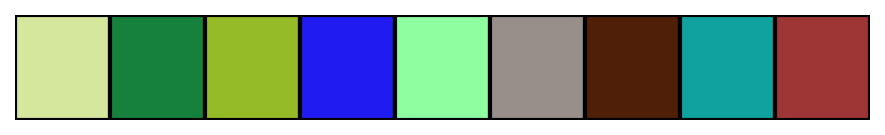

✅ 已生成第 5 张向量图


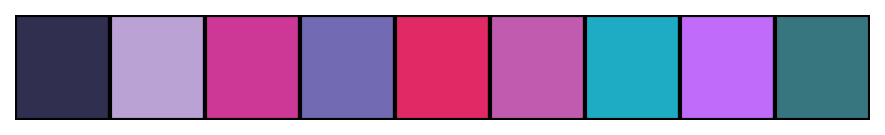

✅ 已生成第 6 张向量图


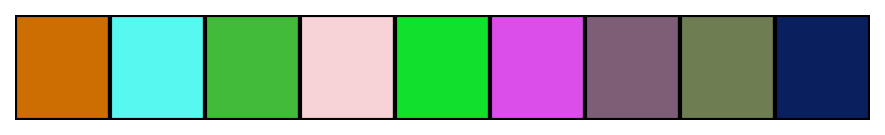

✅ 已生成第 7 张向量图


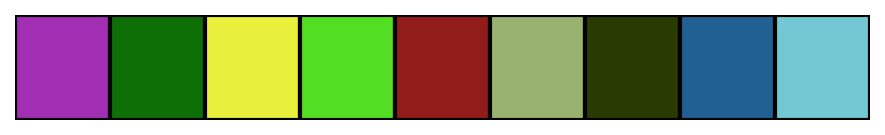

✅ 已生成第 8 张向量图


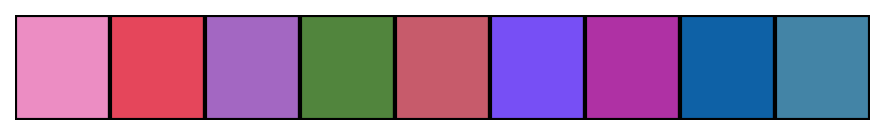

✅ 已生成第 9 张向量图


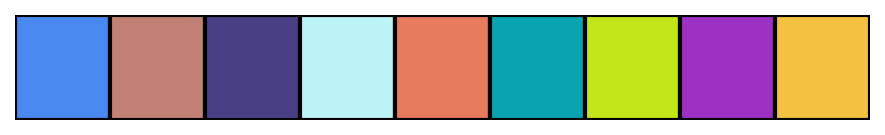

✅ 已生成第 10 张向量图


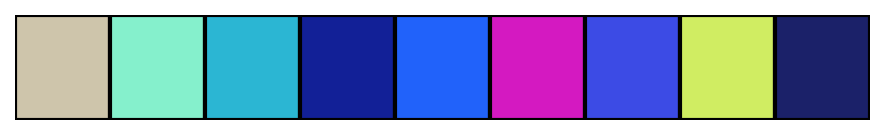

✅ 已生成第 11 张向量图


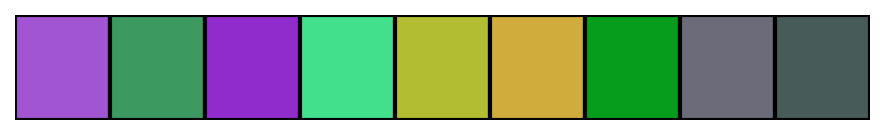

✅ 已生成第 12 张向量图


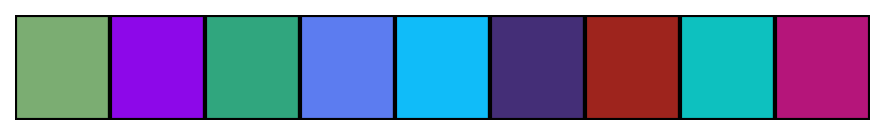

✅ 已生成第 13 张向量图


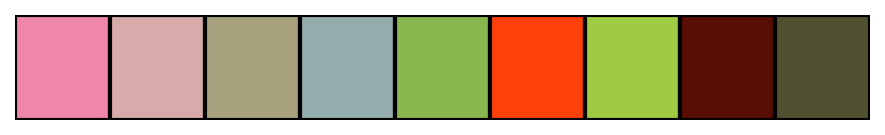

✅ 已生成第 14 张向量图


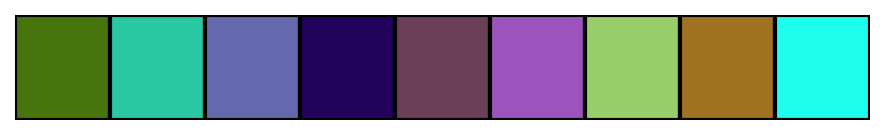

✅ 已生成第 15 张向量图


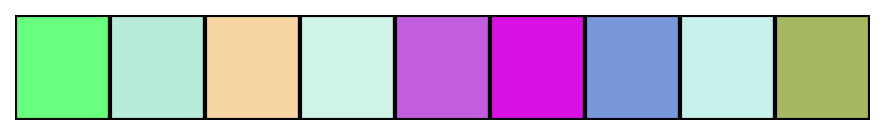

✅ 已生成第 16 张向量图

🎉 全部 16 张已生成（种子=2024）


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import random
from pathlib import Path

# ===================== 可修改参数 =====================
NUM_IMAGES = 16          # 生成多少张
VECTOR_DIM = 9           # 每个向量色块数量
RANDOM_SEED = 2024       # 随机种子（改这个数字就能换一套固定颜色）
# ======================================================

# 固定随机种子 → 保证可复现
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 开始生成
for idx in range(NUM_IMAGES):
    fig, ax = plt.subplots(figsize=(6, 1), dpi=150)
    ax.set_xlim(0, VECTOR_DIM)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # 逐个绘制随机颜色色块
    for i in range(VECTOR_DIM):
        r = random.random()
        g = random.random()
        b = random.random()
        color = (r, g, b)

        rect = plt.Rectangle((i, 0), 1, 1, color=color, ec="black", lw=2)
        ax.add_patch(rect)

    plt.tight_layout()
    plt.show()
    print(f"✅ 已生成第 {idx+1} 张向量图")

print(f"\n🎉 全部 {NUM_IMAGES} 张已生成（种子={RANDOM_SEED}）")

Loading dataset from data/nist23_data/test23/test.json...

==== 查询ID: 279610 ====
找到分子！SMILES: C=CC(CCC)OC
正在绘制质谱图...

==== 查询ID: 279610 ====
找到分子！SMILES: C=CC(CCC)OC
正在绘制质谱图...


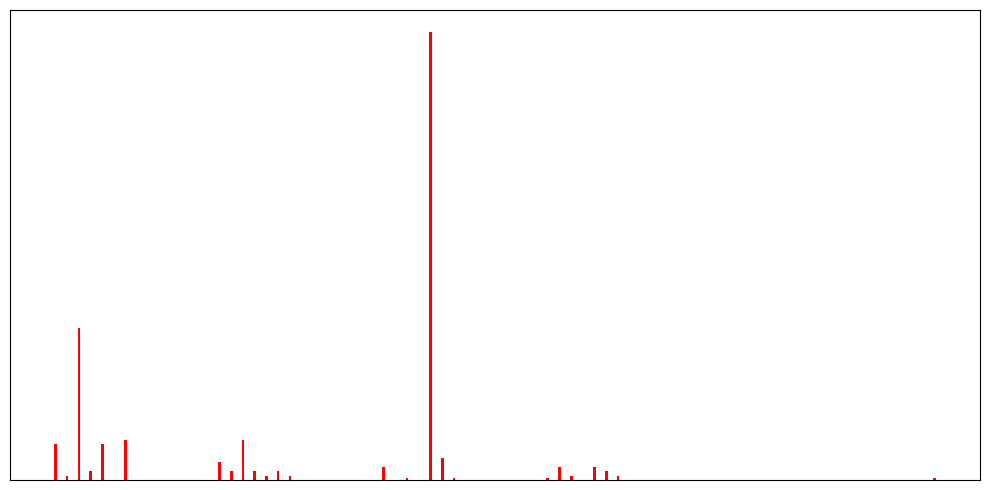


==== 查询ID: 422661 ====
找到分子！SMILES: C=CCCCC
正在绘制质谱图...


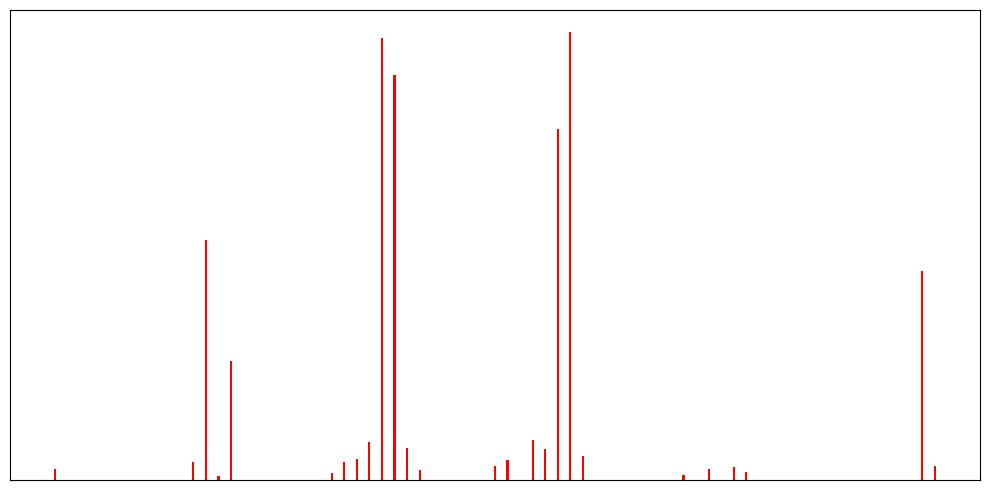


==== 查询ID: 108172 ====
找到分子！SMILES: COC1CCCCC1=O
正在绘制质谱图...


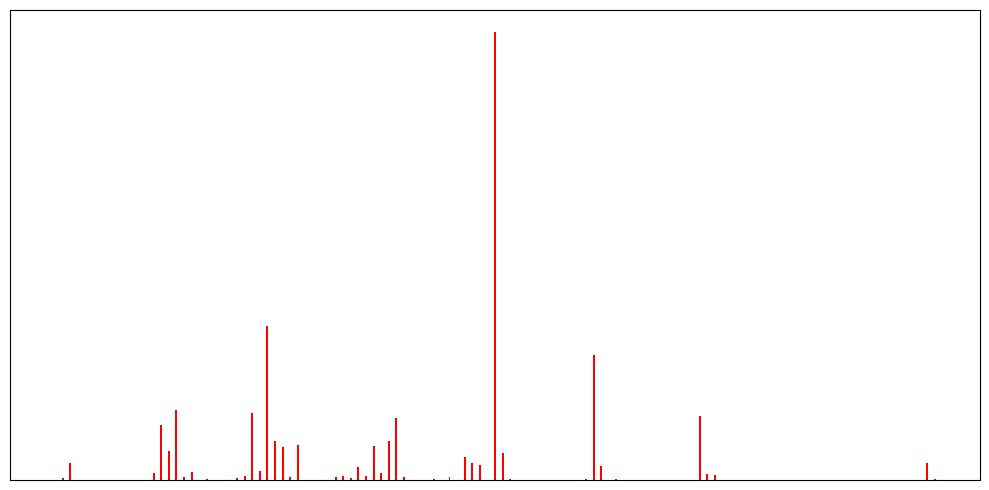


==== 查询ID: 379487 ====
找到分子！SMILES: O=C1CCCCC1
正在绘制质谱图...


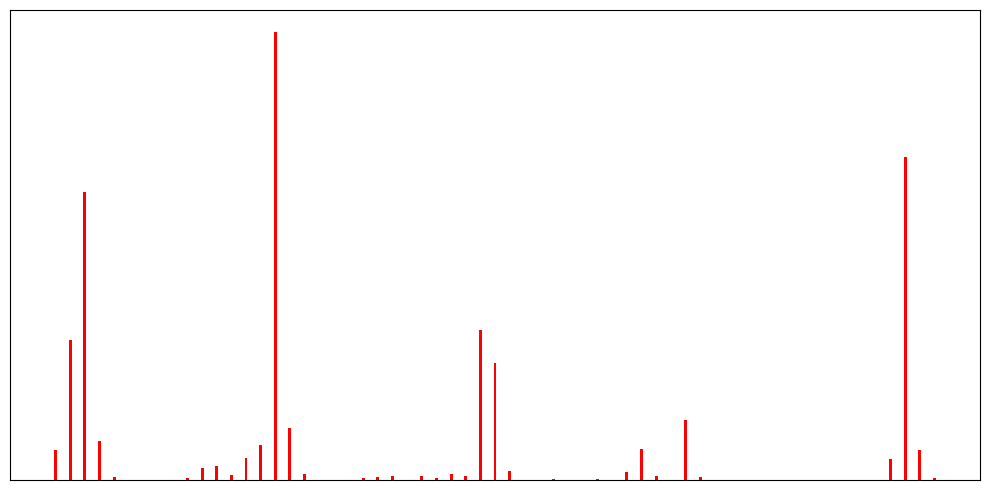

In [6]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import numpy as np
import matplotlib.pyplot as plt

# 1. 设定你要查询的分子ID列表和数据源路径
id_list = ["279610", "422661", "108172", "379487"]  # 依次画出这些ID
# 你可以根据需要继续添加ID

data_path = "data/nist23_data/test23/test.json"

# 2. 读取JSON数据
print(f"Loading dataset from {data_path}...")
with open(data_path, 'r') as f:
    data_list = json.load(f)

# 3. 建立ID与分子信息的映射表
id_map = {str(item.get('nist_id', item.get('id', item.get('nist', '')))): item for item in data_list}

# 4. 依次查找并绘制质谱图（无x/y轴刻度和标签）
for target_id in id_list:
    print(f"\n==== 查询ID: {target_id} ====")
    if target_id in id_map:
        mol_info = id_map[target_id]
        peaks = mol_info.get('peaks')
        print(f"找到分子！SMILES: {mol_info.get('smiles')}")
        print("正在绘制质谱图...")
        # 画图
        peaks = np.array(peaks, dtype=np.float32)
        mz = peaks[:, 0]
        mz_max = mz.max()
        intensity = peaks[:, 1]
        intensity = intensity / intensity.max()
        plt.figure(figsize=(10, 5))
        plt.bar(mz, intensity, width=mz_max/500, color='red')
        plt.xticks([])  # 去掉x轴刻度
        plt.yticks([])  # 去掉y轴刻度
        plt.xlabel("")  # 去掉x轴标签
        plt.ylabel("")  # 去掉y轴标签
        plt.tight_layout()
        plt.show()
    else:
        print(f"在数据集中未找到ID为 {target_id} 的分子，请检查输入是否正确。")